# Entrega 3 · Modelado de etapas del sueño
Notebook autónomo: ejecutar desde el comienzo con los CSV `dataset_epochs_v1.csv` y
`dataset_modelado_candidato.csv` de la misma cohorte. No ejecuta ETL de señales crudas.

La cátedra solicita seleccionar técnicas, parámetros, evaluar e interpretar modelos.
La división por grupos, XGBoost y los diagnósticos adicionales son decisiones metodológicas
del proyecto; no requisitos específicos de algoritmos de la cátedra.

La ejecución anterior queda en `docs/entrega-03/referencia-previa.json` (código y salidas
originales). Los nuevos resultados usan desarrollo reducido y no son réplicas de aquella ejecución.
El test interno tuvo exposición previa en EDA y comparaciones: la evaluación externa futura
con pacientes nuevos permanece pendiente. No usar resultados de test para reajustar.


## 4.1. Datos, test reservado y particiones
Reservamos aproximadamente 20 % de pacientes completos con semilla 42.
Los otros pacientes constituyen desarrollo. Allí comparamos folds por paciente y
folds por epochs mezclados. Estos últimos permiten compartir pacientes entre entrenamiento
y validación y responden una pregunta menos exigente sobre personas desconocidas.
La partición no se elige por sus métricas. Si falta cobertura de una etapa, detener y revisar.


`X` contiene las características de cada epoch; `y` es `Sleep_Stage` y `patient_id` se usa
únicamente para separar personas. El secundario solo wearable se mantiene para después.
La estratificación intenta conservar proporciones, no balancea ni garantiza clases presentes:
por eso comprobamos cobertura. Las tablas muestran solo cantidad de pacientes; compartidos
debe ser cero en el protocolo por pacientes y puede ser mayor que cero al mezclar epochs.
Además se incorpora validación cronológica dentro de cada paciente: seis bloques, cinco validaciones futuras y gap de 15 minutos. El bloque inicial no recibe predicciones OOF.

El escenario conocido presupone observaciones pasadas etiquetadas para entrenamiento; las etiquetas nunca se usan como características de historia al predecir.


In [1]:
from pathlib import Path
import hashlib
import sys
import importlib.metadata
import importlib.util
import json
import platform
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from IPython import get_ipython
if getattr(get_ipython(), 'kernel', None) is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, ConfusionMatrixDisplay, precision_recall_curve,
    average_precision_score, roc_curve, roc_auc_score)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Instalación local opcional; en Kaggle se usa el entorno del notebook.
for carpeta_dependencias in [Path('output/modelado-deps'), Path('../output/modelado-deps')]:
    if carpeta_dependencias.is_dir():
        sys.path.insert(0, str(carpeta_dependencias.resolve()))


def mostrar_tabla(tabla, titulo=None):
    """HTML completo, sin límites globales de pandas ni reducción de fuente."""
    if titulo:
        display(Markdown(f'**{titulo}**'))
    tiene_indice = not isinstance(tabla.index, pd.RangeIndex)
    html = tabla.to_html(index=tiene_indice, border=0, max_rows=None, max_cols=None,
                         float_format=lambda v: f'{v:.4f}', na_rep='—', escape=True)
    display(HTML('<div style="overflow-x:auto; margin-bottom:1em">' + html + '</div>'))

def nombre_protocolo(protocolo):
    return {'pacientes': 'Pacientes separados', 'epochs': 'Epochs mezclados', 'temporal': 'Pacientes conocidos · futuro cronológico'}[protocolo]

def nombre_algoritmo(algoritmo):
    return {'Baseline': 'Referencia trivial', 'Logistica': 'Regresión logística',
            'RF': 'Random Forest', 'XGB': 'XGBoost'}.get(algoritmo, algoritmo)

SEMILLA = 42
N_SPLITS = 5
ETAPAS = ['W', 'N1', 'N2', 'N3', 'R']
CLAVES = ['patient_id', 'epoch']
EN_KAGGLE = platform.system() != 'Windows' and Path('/kaggle/input').is_dir()
SALIDA = Path('/kaggle/working/modelado') if EN_KAGGLE else Path('output/modelado')
SALIDA.mkdir(parents=True, exist_ok=True)

def guardar_json(ruta, objeto):
    ruta.write_text(json.dumps(objeto, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def buscar_csv(nombre):
    # Una ubicación explícita evita elegir silenciosamente entre copias Kaggle.
    locales = [Path('etl_v1') / nombre, Path('../etl_v1') / nombre]
    archivos = [p.resolve() for p in locales if p.exists()]
    if not archivos and EN_KAGGLE:
        archivos = list(Path('/kaggle/input').rglob(nombre))
    archivos = list(dict.fromkeys(archivos))
    if len(archivos) != 1:
        raise FileNotFoundError(f'{nombre}: se esperaba una única fuente; encontradas {archivos}')
    return archivos[0]

ruta_base = buscar_csv('dataset_epochs_v1.csv')
ruta_candidato = buscar_csv('dataset_modelado_candidato.csv')
base = pd.read_csv(ruta_base, low_memory=False)
candidato = pd.read_csv(ruta_candidato, low_memory=False)
versiones = {'python': platform.python_version(), **{
    paquete: importlib.metadata.version(paquete)
    for paquete in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'imbalanced-learn']}}
versiones['xgboost'] = (importlib.metadata.version('xgboost')
    if importlib.util.find_spec('xgboost') else 'no instalado')
guardar_json(SALIDA / 'versiones.json', versiones)
mostrar_tabla(pd.DataFrame([{'fuente': 'ETL', 'epochs': len(base), 'columnas': base.shape[1]},
                      {'fuente': 'candidato', 'epochs': len(candidato), 'columnas': candidato.shape[1]}]))

def particiones_cronologicas(tabla, n_splits=5, gap_segundos=900):
    """Seis bloques por persona; el primero solo inicia entrenamiento."""
    bloques = np.full(len(tabla), -1, dtype=int)
    for _, grupo in tabla.groupby('patient_id', sort=False):
        orden = grupo.sort_values('tiempo_relativo_segundos').index.to_numpy()
        if grupo.tiempo_relativo_segundos.duplicated().any():
            raise ValueError('Tiempo repetido dentro de paciente')
        for b, indices in enumerate(np.array_split(orden, n_splits + 1)):
            bloques[indices] = b
    rondas = []
    for b in range(1, n_splits + 1):
        validacion, entrenamiento = [], []
        for _, grupo in tabla.groupby('patient_id', sort=False):
            va = grupo.index[bloques[grupo.index] == b].to_numpy()
            if not len(va):
                continue
            corte = tabla.loc[va, 'tiempo_relativo_segundos'].min() - gap_segundos
            tr = grupo.index[(bloques[grupo.index] < b) &
                (grupo.tiempo_relativo_segundos.to_numpy() < corte)].to_numpy()
            if not len(tr):
                raise ValueError('Paciente sin historia suficiente para entrenamiento cronológico')
            entrenamiento.extend(tr); validacion.extend(va)
        rondas.append((np.sort(entrenamiento), np.sort(validacion)))
    return rondas, bloques

def agregar_historia(entradas, tabla, minutos):
    """Solo pasado exacto dentro de segmentos de epochs contiguos de 30 s."""
    if not entradas.index.equals(tabla.index):
        raise ValueError('Historia desalineada')
    salida = entradas.copy()
    disponibilidad = []
    for _, grupo in tabla.groupby('patient_id', sort=False):
        orden = grupo.sort_values('tiempo_relativo_segundos').index
        tiempos = tabla.loc[orden, 'tiempo_relativo_segundos']
        if tiempos.duplicated().any() or not np.isfinite(tiempos).all():
            raise ValueError('Tiempos inválidos para historia')
    ordenada = tabla.sort_values(['patient_id', 'tiempo_relativo_segundos'])
    salto = ordenada.groupby('patient_id').tiempo_relativo_segundos.diff()
    segmentos = (~np.isclose(salto.to_numpy(), 30.0, atol=1e-6, rtol=0)).cumsum()
    grupos = ordenada.assign(segmento=segmentos).groupby(['patient_id','segmento'], sort=False)
    for minuto in minutos:
        pasos = int(round(minuto * 2))
        if pasos <= 0 or not np.isclose(pasos * 30, minuto * 60):
            raise ValueError('Retardo no compatible con epochs de 30 segundos')
        columnas = [f'{c}__lag{minuto}m' for c in entradas]
        historia = pd.DataFrame(np.nan, index=entradas.index, columns=entradas.columns)
        for _, grupo in grupos:
            historia.loc[grupo.index] = entradas.loc[grupo.index].shift(pasos).to_numpy()
        historia.columns = columnas
        indicador = f'historia_disponible__lag{minuto}m'
        salida = pd.concat([salida, historia], axis=1)
        salida[indicador] = historia.notna().all(axis=1).astype(int)
        disponibilidad.append(dict(minutos=minuto, disponibles=int(salida[indicador].sum()),
            faltantes=int((salida[indicador] == 0).sum()), fraccion=float(salida[indicador].mean())))
    return salida, pd.DataFrame(disponibilidad)


fuente,epochs,columnas
ETL,56850,128
candidato,56850,26


In [2]:
columnas_principal = [
    'HR_median', 'HR_std', 'TEMP_median', 'EDA_std',
    'C4-M1_std', 'F4-M1_std', 'O2-M1_std', 'Fp1-O2_std',
    'T3 - CZ_std', 'CZ - T4_std', 'CHIN_std', 'ECG_std',
    'SNORE_std', 'PTAF_std', 'FLOW_std', 'THORAX_std', 'ABDOMEN_std',
    'EOG_max_std', 'LEG_max_std', 'BVP_std_log1p',
    'EDA_median_log1p', 'ACC_axes_std_norm_log1p']
for nombre, tabla in [('ETL', base), ('candidato', candidato)]:
    if tabla[CLAVES + ['Sleep_Stage']].isna().any().any():
        raise ValueError(f'{nombre}: identidad u objetivo faltante')
    if tabla.duplicated(CLAVES).any():
        raise ValueError(f'{nombre}: claves repetidas')
    if not tabla.Sleep_Stage.isin(ETAPAS).all():
        raise ValueError(f'{nombre}: etapas inválidas')
base = base.sort_values(CLAVES).reset_index(drop=True)
candidato = candidato.sort_values(CLAVES).reset_index(drop=True)
if not base[CLAVES + ['Sleep_Stage']].equals(candidato[CLAVES + ['Sleep_Stage']]):
    raise ValueError('Los CSV no tienen la misma cohorte, claves y etiquetas. '
                     'Exportar ambos desde la misma ejecución; no se recortan ni reconstruyen datos.')
assert not set(columnas_principal) & set(CLAVES + ['Sleep_Stage', 'tiempo_relativo_segundos'])
if not np.isfinite(candidato[columnas_principal].to_numpy(dtype=float)).all():
    raise ValueError('Hay predictores faltantes o infinitos; revisar ETL.')

# Huella de ambos archivos: una asignación guardada no se reutiliza con otros datos.
def sha256_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()
huella = {p.name: sha256_archivo(p) for p in [ruta_base, ruta_candidato]}
ruta_asignacion = SALIDA / 'asignacion_pacientes.json'
if ruta_asignacion.exists():
    asignacion = json.loads(ruta_asignacion.read_text(encoding='utf-8'))
    if asignacion['huella'] != huella or asignacion['semilla'] != SEMILLA:
        raise ValueError('Cambió la fuente/semilla: conservar las salidas anteriores y usar otra carpeta SALIDA.')
    pacientes_test = asignacion['pacientes_test']
else:
    division = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
    _, idx_test = next(division.split(base, groups=base.patient_id))
    pacientes_test = sorted(base.iloc[idx_test].patient_id.unique().tolist())
    asignacion = {'huella': huella, 'semilla': SEMILLA, 'fraccion_pacientes_test': 0.2,
                  'pacientes_test': pacientes_test,
                  'exposicion_previa': 'EDA y comparaciones anteriores sobre la cohorte completa'}

es_test = base.patient_id.isin(pacientes_test)
for nombre, tabla in [('desarrollo', base.loc[~es_test]), ('test', base.loc[es_test])]:
    if set(tabla.Sleep_Stage) != set(ETAPAS):
        raise ValueError(f'{nombre}: falta alguna etapa. Revisar cobertura antes de entrenar, sin elegir por desempeño.')
guardar_json(ruta_asignacion, asignacion)
asignacion_csv = base[CLAVES].assign(conjunto=np.where(es_test, 'test', 'desarrollo'))
asignacion_csv.to_csv(SALIDA / 'asignacion_epochs.csv', index=False)
dev = candidato.loc[~es_test].reset_index(drop=True)
base_dev = base.loc[~es_test].reset_index(drop=True)
test = candidato.loc[es_test].reset_index(drop=True)
assert not set(dev.patient_id) & set(test.patient_id)
assert len(dev) + len(test) == len(base)
y = dev.Sleep_Stage.map({e: i for i, e in enumerate(ETAPAS)}).to_numpy()
X = dev[columnas_principal]
folds = {
    'pacientes': list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEMILLA)
                      .split(X, y, dev.patient_id)),
    'epochs': list(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEMILLA).split(X, y))}
controles, asignaciones_folds, pacientes_folds = [], [], []
for protocolo, rondas in folds.items():
    cobertura = np.zeros(len(dev), dtype=int)
    for fold, (tr, va) in enumerate(rondas, 1):
        assert not set(tr) & set(va)
        assert len(tr) + len(va) == len(dev)
        if protocolo == 'pacientes':
            assert not set(dev.iloc[tr].patient_id) & set(dev.iloc[va].patient_id)
        pacientes_folds.append({'protocolo': protocolo, 'Fold': fold,
            'Entrenamiento': dev.iloc[tr].patient_id.nunique(),
            'Validación': dev.iloc[va].patient_id.nunique(),
            'Compartidos': len(set(dev.iloc[tr].patient_id) & set(dev.iloc[va].patient_id))})
        cobertura[va] += 1
        asignaciones_folds.append(dev.iloc[va][CLAVES].assign(protocolo=protocolo, fold=fold))
        for conjunto, idx in [('entrenamiento', tr), ('validacion', va)]:
            if set(y[idx]) != set(range(5)):
                raise ValueError(f'{protocolo}, fold {fold}: cobertura incompleta')
            for codigo, etapa in enumerate(ETAPAS):
                controles.append(dict(protocolo=protocolo, fold=fold, conjunto=conjunto,
                    etapa=etapa, epochs=int((y[idx] == codigo).sum()),
                    pacientes=dev.iloc[idx].loc[y[idx] == codigo, 'patient_id'].nunique()))
    assert (cobertura == 1).all()
pd.concat(asignaciones_folds).to_csv(SALIDA / 'folds_validacion.csv', index=False)
pd.DataFrame(controles).to_csv(SALIDA / 'cobertura_folds.csv', index=False)

mostrar_tabla(asignacion_csv.groupby('conjunto').agg(Pacientes=('patient_id', 'nunique'))
              .rename_axis('Conjunto'), 'Reserva de pacientes')
pacientes_folds = pd.DataFrame(pacientes_folds)
pacientes_folds.to_csv(SALIDA / 'pacientes_por_fold.csv', index=False)
for protocolo in folds:
    tabla = pacientes_folds.loc[pacientes_folds.protocolo.eq(protocolo)].drop(columns='protocolo').reset_index(drop=True)
    mostrar_tabla(tabla, f'Pacientes por fold — {nombre_protocolo(protocolo)}')
print('Cobertura de las cinco etapas verificada. Detalle por etapa guardado en cobertura_folds.csv.')


**Reserva de pacientes**

,Pacientes
Conjunto,
desarrollo,60
test,16


**Pacientes por fold — Pacientes separados**

Fold,Entrenamiento,Validación,Compartidos
1,49,11,0
2,47,13,0
3,48,12,0
4,47,13,0
5,49,11,0


**Pacientes por fold — Epochs mezclados**

Fold,Entrenamiento,Validación,Compartidos
1,60,60,60
2,60,60,60
3,60,60,60
4,60,60,60
5,60,60,60


Cobertura de las cinco etapas verificada. Detalle por etapa guardado en cobertura_folds.csv.


In [3]:
folds['temporal'], bloques_temporales = particiones_cronologicas(dev)
cobertura_temporal = np.zeros(len(dev), dtype=int)
filas = []
for numero, (tr, va) in enumerate(folds['temporal'], 1):
    assert not set(tr) & set(va)
    assert set(y[tr]) == set(range(5)), 'Falta clase en entrenamiento cronológico'
    cobertura_temporal[va] += 1
    for paciente in dev.iloc[va].patient_id.unique():
        a = dev.iloc[tr].query('patient_id == @paciente').tiempo_relativo_segundos
        b = dev.iloc[va].query('patient_id == @paciente').tiempo_relativo_segundos
        assert a.max() < b.min() - 900
    for conjunto, idx in [('entrenamiento',tr),('validacion',va)]:
        for c,e in enumerate(ETAPAS):
            filas.append(dict(fold=numero, conjunto=conjunto, etapa=e, epochs=int((y[idx]==c).sum())))
assert np.array_equal(cobertura_temporal, (bloques_temporales > 0).astype(int))
pd.DataFrame(filas).to_csv(SALIDA / 'cobertura_temporal.csv', index=False)
pd.concat([dev.iloc[va][CLAVES].assign(fold=k) for k,(_,va) in enumerate(folds['temporal'],1)]).to_csv(
    SALIDA / 'folds_temporales.csv', index=False)
dev[CLAVES].assign(bloque=bloques_temporales, evaluable=bloques_temporales>0).to_csv(
    SALIDA / 'elegibilidad_temporal.csv', index=False)
mostrar_tabla(pd.DataFrame([dict(Fold=k, Entrenamiento=dev.iloc[tr].patient_id.nunique(),
    Validacion=dev.iloc[va].patient_id.nunique()) for k,(tr,va) in enumerate(folds['temporal'],1)]),
    'Pacientes por fold cronológico')
print(f'Cronológico: {int((bloques_temporales>0).sum())} epochs de validación; '
      f'{int((bloques_temporales==0).sum())} epochs iniciales solo para entrenamiento. Gap: 15 minutos.')
print('Clases ausentes por bloque, si las hay, quedan en cobertura_temporal.csv; F1 usa siempre cinco clases.')


**Pacientes por fold cronológico**

Fold,Entrenamiento,Validacion
1,60,60
2,60,60
3,60,60
4,60,60
5,60,60


Cronológico: 37490 epochs de validación; 7521 epochs iniciales solo para entrenamiento. Gap: 15 minutos.
Clases ausentes por bloque, si las hay, quedan en cobertura_temporal.csv; F1 usa siempre cinco clases.


## 4.2. Configuraciones y reproducibilidad
DummyClassifier es el piso; logística es la referencia lineal. RF y XGBoost capturan
interacciones no lineales. Ninguno es ganador por definición. Semilla y núcleos controlan
reproducibilidad/costo, no se optimizan como capacidad predictiva.
Los hiperparámetros, sus efectos y las variaciones están documentados en
`docs/entrega-03/experimentos-hiperparametros.md`. No hay SMOTE inicial.


### Referencia trivial

Se utiliza `DummyClassifier` con la estrategia `most_frequent`: en cada fold identifica la etapa más frecuente del entrenamiento y la predice para todos los epochs de validación.

Este baseline establece una referencia mínima. Los modelos posteriores deberían mejorar su desempeño, especialmente en F1 macro y en el reconocimiento de las etapas minoritarias. Se evalúa con las mismas particiones y métricas que los demás candidatos.

### Regresión logística multiclase

Se utiliza regresión logística como referencia lineal para clasificar las cinco etapas. Las variables se estandarizan con `StandardScaler`, ajustado únicamente con el entrenamiento de cada fold.

Configuración inicial:

* `C=1.0`: controla la intensidad de la regularización, que penaliza coeficientes grandes para limitar ajustes demasiado específicos al entrenamiento. Un C menor aplica mayor regularización; uno mayor, menor. Se utiliza 1 como referencia inicial, sin considerarlo óptimo.
* `solver="lbfgs"`: algoritmo de optimización que encuentra los coeficientes del modelo. Permite ajustar la clasificación multiclase.
* `max_iter=2000`: máximo de iteraciones del optimizador. Si converge antes, se detiene antes. Este límite busca permitir que termine el ajuste; no garantiza mejores predicciones.
* `escalar=True`: activa la estandarización dentro del Pipeline. Cada variable se centra y divide por su desviación estándar calculada en entrenamiento.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos. En 4.4 se compara también con pesos, manteniendo los demás parámetros.

### Random Forest

Random Forest combina árboles de decisión entrenados con variaciones en los datos y las características consideradas. Permite representar relaciones no lineales e interacciones entre señales.

Configuración inicial:

* `n_estimators=200`: cantidad de árboles del bosque. Se parte de 200 para obtener una primera referencia con un costo de ejecución acotado.
* `min_samples_leaf=2`: cada hoja debe contener al menos dos observaciones de entrenamiento. Limita hojas demasiado específicas, aunque no garantiza evitar el sobreajuste.
* `max_features="sqrt"`: en cada división se considera un subconjunto aleatorio de características cuyo tamaño depende de la raíz cuadrada del número de predictores. Favorece que los árboles sean diferentes entre sí.
* `escalar=False`: no se estandarizan las variables; los árboles realizan divisiones mediante umbrales por característica.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos.

Opciones de ejecución:

* `random_state=SEMILLA`: fija la aleatoriedad para poder reproducir el experimento con los mismos datos y configuración.
* `n_jobs=-1`: permite utilizar los núcleos de CPU disponibles para paralelizar el trabajo.

### XGBoost

XGBoost aplica gradient boosting: incorpora árboles secuencialmente para reducir la función de pérdida del conjunto. Se evalúa como candidato para capturar relaciones no lineales entre las señales.

Configuración inicial:

* `objective="multi:softprob"`: define un problema de clasificación multiclase y permite obtener probabilidades para cada etapa.
* `num_class=5`: indica las cinco clases: W, N1, N2, N3 y R.
* `n_estimators=200`: establece 200 rondas de boosting. En clasificación multiclase, una ronda puede incorporar varios árboles.
* `max_depth=4`: limita la profundidad de los árboles. Se parte de árboles relativamente acotados para controlar complejidad y costo.
* `learning_rate=0.1`: reduce la contribución de cada ronda al conjunto. Valores menores suelen requerir más rondas para aprender.
* `subsample=0.8`: utiliza una muestra aleatoria del 80 % de las observaciones de entrenamiento en cada ronda.
* `colsample_bytree=0.8`: utiliza una muestra aleatoria del 80 % de las características al construir cada árbol. Ambos muestreos introducen variación y pueden ayudar a limitar el sobreajuste.
* `eval_metric="mlogloss"`: configura la pérdida logarítmica multiclase como métrica interna. La comparación entre candidatos sigue usando F1 macro como métrica principal. En esta ejecución no se utiliza early stopping.
* `escalar=False`: se mantienen las escalas de las variables para este modelo basado en árboles.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos.

Opciones de ejecución:

* `tree_method="hist"`: utiliza histogramas para buscar divisiones de forma eficiente.
* `random_state=SEMILLA`: fija la aleatoriedad del experimento.
* `n_jobs=-1`: permite utilizar los núcleos de CPU disponibles.


In [4]:
def modelos_referencia():
    try:
        from xgboost import XGBClassifier
    except ImportError as exc:
        raise ImportError('Instalar xgboost en el entorno elegido antes de entrenar; no se omite el candidato.') from exc
    return {
        'Baseline': (DummyClassifier(strategy='most_frequent'), False),
        'Logistica': (LogisticRegression(C=1, solver='lbfgs', max_iter=2000), True),
        'RF': (RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                 max_features='sqrt', random_state=SEMILLA, n_jobs=-1), False),
        'XGB': (XGBClassifier(objective='multi:softprob', num_class=5, n_estimators=200,
                 max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                 tree_method='hist', eval_metric='mlogloss', random_state=SEMILLA, n_jobs=-1), False)}


## 4.3. Evaluación común
`X` contiene predictores; `y`, las cinco etapas codificadas; pacientes e identidad quedan aparte.
Cada fold crea un pipeline nuevo. El escalado y los pesos se ajustan únicamente en entrenamiento.
Peso balanceado por clase: `N_train / (5 * N_clase_train)`; no combina además `class_weight`.

Guardamos métricas de entrenamiento y validación, tiempos y probabilidades OOF:
cada epoch elegible recibe una predicción de validación por configuración. F1 macro da igual peso a las
cinco etapas; soporte es cantidad real de ejemplos. Brecha alta con entrenamiento sugiere
sobreajuste; ambos resultados bajos no identifican por sí solos su causa.


El pipeline reúne preprocesamiento y clasificador: se crea una instancia nueva por fold.
Logística estandariza con StandardScaler aprendido en entrenamiento; los árboles no lo necesitan.
Las probabilidades se guardan en orden explícito para construir curvas posteriormente.
En pacientes separados, una predicción OOF nunca proviene de un modelo que vio a esa persona;
con epochs mezclados, esa garantía se limita al epoch retenido.

**Cómo leer las métricas:** precisión indica qué proporción de detecciones de una etapa es
correcta; recuperación, qué proporción de sus casos reales se detectó. F1 combina ambas:
`2 × precisión × recuperación / (precisión + recuperación)`. F1 macro promedia los cinco F1
con igual peso. Exactitud es la fracción total de aciertos y soporte es cantidad de casos reales.
La referencia trivial puede acertar N2 frecuentemente sin reconocer las otras cuatro etapas.

**Pesos automáticos:** compute_sample_weight("balanced") asigna `N_train / (5 × N_clase_train)`
a cada observación. Se recalculan dentro del fold, no crean ejemplos y pueden aumentar
recuperación minoritaria a costa de falsos positivos. Validación y test no se ponderan.
La tabla de pesos por etapa queda exportada con cada experimento.
Los códigos 0–4 identifican clases; no representan un orden entre etapas. Las señales PSG pueden entrar en X, pero Sleep_Stage es exclusivamente y.

SMOTE y contexto temporal se comparan por separado, con preprocesamiento ajustado por fold.


In [5]:
def crear_pipeline(modelo, escalar=False, imputar=False, smote=None):
    pasos = [('imputacion', SimpleImputer(strategy='median', keep_empty_features=True) if imputar else 'passthrough'),
             ('escala', StandardScaler() if escalar or smote else 'passthrough')]
    if smote:
        from imblearn.over_sampling import SMOTE
        from imblearn.pipeline import Pipeline as PipelineMuestreo
        pasos += [('smote', SMOTE(sampling_strategy=smote['cantidades'],
                                  k_neighbors=smote['k'], random_state=SEMILLA)), ('modelo', clone(modelo))]
        return PipelineMuestreo(pasos)
    return Pipeline(pasos + [('modelo', clone(modelo))])

def evaluar(modelo, entradas, nombre, protocolo, pesos=False, escalar=False, importancia=False,
            mostrar_progreso=True, imputar=False, smote=None):
    if (not entradas.index.equals(dev.index) or np.isinf(entradas.to_numpy(float)).any()
        or (not imputar and entradas.isna().any().any())):
        raise ValueError('Entradas desalineadas o no finitas')
    if set(entradas.columns) & set(CLAVES + ['Sleep_Stage', 'tiempo_relativo_segundos']):
        raise ValueError('Identificador, tiempo u objetivo entre entradas')
    metricas, etapas, predicciones, pesos_folds, importancias = [], [], [], [], []
    muestreo = []
    if smote and pesos:
        raise ValueError('No combinar SMOTE y pesos en esta ronda')
    for numero, (tr, va) in enumerate(folds[protocolo], 1):
        opciones_smote = None
        cantidades = np.bincount(y[tr], minlength=5)
        if smote:
            objetivo = int(np.ceil(cantidades.max() * smote['ratio']))
            estrategia = {c: max(int(n), objetivo) for c,n in enumerate(cantidades)}
            if cantidades.min() <= smote['k']:
                raise ValueError('SMOTE sin vecinos suficientes; no modificar k silenciosamente')
            opciones_smote = dict(k=smote['k'], cantidades=estrategia)
        pipe = crear_pipeline(modelo, escalar, imputar, opciones_smote)
        for c,e in enumerate(ETAPAS):
            muestreo.append(dict(fold=numero, etapa=e, reales=int(cantidades[c]),
                sinteticos=0 if not smote else estrategia[c]-int(cantidades[c])))
        w = compute_sample_weight('balanced', y[tr]) if pesos else np.ones(len(tr))
        for c, etapa in enumerate(ETAPAS):
            pesos_folds.append(dict(fold=numero, etapa=etapa, epochs=int((y[tr] == c).sum()),
                                    peso=float(w[y[tr] == c][0])))
        inicio = perf_counter()
        if smote:
            pipe.fit(entradas.iloc[tr], y[tr])
        else:
            pipe.fit(entradas.iloc[tr], y[tr], modelo__sample_weight=w)
        t_fit = perf_counter() - inicio
        for conjunto, idx in [('entrenamiento', tr), ('validacion', va)]:
            inicio = perf_counter()
            pred = pipe.predict(entradas.iloc[idx]).astype(int)
            prob = pipe.predict_proba(entradas.iloc[idx]) if conjunto == 'validacion' else None
            t_pred = perf_counter() - inicio
            metricas.append(dict(experimento=nombre, protocolo=protocolo, pesos=pesos,
                fold=numero, conjunto=conjunto,
                f1_macro=f1_score(y[idx], pred, labels=range(5), average='macro', zero_division=0),
                exactitud=accuracy_score(y[idx], pred), segundos_entrenamiento=t_fit,
                segundos_prediccion=t_pred))
            p, r, f, s = precision_recall_fscore_support(y[idx], pred, labels=range(5), zero_division=0)
            for c, etapa in enumerate(ETAPAS):
                etapas.append(dict(fold=numero, conjunto=conjunto, etapa=etapa,
                    precision=p[c], recuperacion=r[c], f1=f[c], soporte=int(s[c])))
            if conjunto == 'validacion':
                assert np.array_equal(pipe.classes_, np.arange(5))
                assert np.isfinite(prob).all() and np.allclose(prob.sum(axis=1), 1)
                salida = dev.iloc[idx][CLAVES + ['tiempo_relativo_segundos']].copy()
                salida['fold'] = numero
                salida['real'] = y[idx]
                salida['predicha'] = pred
                for c, etapa in enumerate(ETAPAS):
                    salida[f'prob_{etapa}'] = prob[:, c]
                predicciones.append(salida)
        if importancia:
            resultado = permutation_importance(pipe, entradas.iloc[va], y[va],
                scoring='f1_macro', n_repeats=5, random_state=SEMILLA + numero, n_jobs=1)
            for j, variable in enumerate(entradas.columns):
                for repeticion, valor in enumerate(resultado.importances[j], 1):
                    importancias.append(dict(fold=numero, variable=variable,
                                              repeticion=repeticion, caida_f1_macro=valor))
        if mostrar_progreso:
            print(f'Fold {numero}/{len(folds[protocolo])} terminado.', flush=True)
    oof = pd.concat(predicciones).sort_index()
    elegibles = np.sort(np.concatenate([va for _,va in folds[protocolo]]))
    assert len(np.unique(elegibles)) == len(elegibles)
    assert np.array_equal(oof.index.to_numpy(), elegibles) and not oof.duplicated(CLAVES).any()
    resultado = dict(metricas=pd.DataFrame(metricas), etapas=pd.DataFrame(etapas),
        oof=oof, pesos=pd.DataFrame(pesos_folds), importancia=pd.DataFrame(importancias),
        configuracion=dict(nombre=nombre, protocolo=protocolo, pesos=pesos, escalar=escalar,
                           columnas=list(entradas.columns), parametros=modelo.get_params(), imputar=imputar, smote=smote),
        muestreo=pd.DataFrame(muestreo))
    carpeta = SALIDA / nombre
    carpeta.mkdir(exist_ok=True)
    for clave in ['metricas', 'etapas', 'oof', 'pesos', 'importancia', 'muestreo']:
        resultado[clave].to_csv(carpeta / f'{clave}.csv', index=False)
    guardar_json(carpeta / 'configuracion.json', resultado['configuracion'])
    return resultado



def algoritmo_resultado(nombre):
    for algoritmo in ['Baseline', 'Logistica', 'RF', 'XGB']:
        if f'_{algoritmo}_' in nombre or nombre.endswith('_' + algoritmo):
            return algoritmo
    return nombre

def etiqueta_resultado(nombre, resultado):
    if resultado['configuracion'].get('descripcion'):
        return (resultado['configuracion']['descripcion'].replace('sin_log_combinada','sin log1p; canales combinados').replace('separada_con_log','canales separados; con log1p').replace('candidata','representación candidata') + (' · pesos balanceados' if resultado['configuracion']['pesos'] else ' · sin pesos'))
    algoritmo = algoritmo_resultado(nombre)
    texto = nombre_algoritmo(algoritmo)
    if algoritmo != 'Baseline':
        texto += ' con pesos' if resultado['configuracion']['pesos'] else ' sin pesos'
    if nombre.startswith('ajuste_'):
        cambio = nombre.split('_pesos', 1)[1].split('_', 1)[1]
        parametro, valor = cambio.rsplit('_', 1)
        texto += f' · {parametro}={valor}'
    elif nombre.startswith('representacion_'):
        variante = nombre.split('_', 2)[2]
        texto += ' · ' + {'candidata': 'candidata', 'sin_log_combinada': 'sin log1p',
                          'separada_con_log': 'canales separados'}.get(variante, variante)
    return texto

def construir_resumen(resultados):
    filas = []
    for nombre, r in resultados.items():
        m = r['metricas']
        va = m.loc[m.conjunto.eq('validacion')]
        tr = m.loc[m.conjunto.eq('entrenamiento')]
        filas.append(dict(experimento=nombre, f1_macro=va.f1_macro.mean(),
            desviacion=va.f1_macro.std(), f1_train=tr.f1_macro.mean(),
            brecha=tr.f1_macro.mean() - va.f1_macro.mean(), exactitud=va.exactitud.mean(),
            segundos_entrenamiento=va.segundos_entrenamiento.sum(),
            segundos_prediccion=va.segundos_prediccion.sum()))
    return pd.DataFrame(filas).set_index('experimento').sort_values('f1_macro', ascending=False)

def mostrar_resultados_modelo(resultado):
    m = resultado['metricas']
    va = m.loc[m.conjunto.eq('validacion')].set_index('fold')
    tr = m.loc[m.conjunto.eq('entrenamiento')].set_index('fold')
    mostrar_tabla(va[['f1_macro', 'exactitud', 'segundos_entrenamiento', 'segundos_prediccion']]
        .rename(columns={'f1_macro': 'F1 macro', 'exactitud': 'Exactitud',
                         'segundos_entrenamiento': 'Entrenamiento (s)',
                         'segundos_prediccion': 'Predicción (s)'}).rename_axis('Fold'), 'Resultados por fold')
    mostrar_tabla(va[['f1_macro', 'exactitud']].agg(['mean', 'std']).T
        .rename(index={'f1_macro': 'F1 macro', 'exactitud': 'Exactitud'},
                columns={'mean': 'Promedio', 'std': 'Desviación estándar'}), 'Promedio y variación entre folds')
    diagnostico = pd.DataFrame({'F1 entrenamiento': tr.f1_macro, 'F1 validación': va.f1_macro,
                                'Brecha': tr.f1_macro - va.f1_macro}).rename_axis('Fold')
    mostrar_tabla(diagnostico, 'Entrenamiento frente a validación')
    etapa = resultado['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    mostrar_tabla(etapa.rename(index={'R': 'REM'}, columns={'precision': 'Precisión',
        'recuperacion': 'Recuperación', 'f1': 'F1'}).rename_axis('Etapa'), 'Métricas por etapa — promedio entre folds')

def resumir(resultados, limite_por_modelo=None, comparar_pesos=False):
    resumen = construir_resumen(resultados)
    protocolos = list(dict.fromkeys(r['configuracion']['protocolo'] for r in resultados.values()))
    for protocolo in protocolos:
        display(Markdown(f'### {nombre_protocolo(protocolo)}'))
        nombres = [x for x in resumen.index if resultados[x]['configuracion']['protocolo'] == protocolo]
        if limite_por_modelo:
            nombres = [x for a in ['Baseline', 'Logistica', 'RF', 'XGB']
                       for x in [z for z in nombres if algoritmo_resultado(z) == a][:limite_por_modelo]]
            print(f'Se muestran hasta {limite_por_modelo} configuraciones por algoritmo; todas están exportadas.')
        tabla = resumen.loc[nombres].copy()
        tabla.index = pd.Index([etiqueta_resultado(x, resultados[x]) for x in nombres], name='Modelo')
        mostrar_tabla(tabla[['f1_macro', 'desviacion', 'exactitud']].rename(columns={
            'f1_macro': 'F1 macro promedio', 'desviacion': 'Desviación estándar', 'exactitud': 'Exactitud'}),
            'Comparación general — validación')
        mostrar_tabla(tabla[['f1_train', 'f1_macro', 'brecha']].rename(columns={
            'f1_train': 'F1 entrenamiento', 'f1_macro': 'F1 validación', 'brecha': 'Brecha'}),
            'Diagnóstico de sobreajuste')
        mostrar_tabla(tabla[['segundos_entrenamiento', 'segundos_prediccion']].rename(columns={
            'segundos_entrenamiento': 'Entrenamiento total (s)', 'segundos_prediccion': 'Predicción total (s)'}),
            'Costo de los cinco folds')
        f1_etapas = pd.DataFrame({etiqueta_resultado(x, resultados[x]): resultados[x]['etapas']
            .query("conjunto == 'validacion'").groupby('etapa').f1.mean().reindex(ETAPAS)
            for x in nombres}).T
        mostrar_tabla(f1_etapas.rename(columns={'R': 'REM'}).rename_axis('Modelo'), 'F1 por etapa — promedio entre folds')
        if comparar_pesos:
            for a in ['Logistica', 'RF', 'XGB']:
                sin, con = f'{protocolo}_{a}_pesos0', f'{protocolo}_{a}_pesos1'
                if sin not in resultados or con not in resultados:
                    continue
                vistas = []
                for nombre, sufijo in [(sin, 'sin pesos'), (con, 'con pesos')]:
                    t = resultados[nombre]['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
                        ['precision', 'recuperacion']].mean().reindex(ETAPAS)
                    vistas.append(t.rename(columns={'precision': f'Precisión {sufijo}',
                                                   'recuperacion': f'Recuperación {sufijo}'}))
                mostrar_tabla(pd.concat(vistas, axis=1).rename(index={'R': 'REM'}).rename_axis('Etapa'),
                              f'{nombre_algoritmo(a)} — efecto de los pesos')
        mejor = resumen.loc[[x for x in resumen.index if resultados[x]['configuracion']['protocolo'] == protocolo]].iloc[0]
        print('Mayor F1 macro en este protocolo:', etiqueta_resultado(mejor.name, resultados[mejor.name]),
              f'({mejor.f1_macro:.4f}). Revisar etapas, dispersión y costo.')
    return resumen

def comparar_prueba(nombre, resultado, referencia_nombre, referencia, tipo, cambio):
    va = resultado['metricas'].query("conjunto == 'validacion'").set_index('fold')
    tr = resultado['metricas'].query("conjunto == 'entrenamiento'").set_index('fold')
    vr = referencia['metricas'].query("conjunto == 'validacion'").set_index('fold')
    tt = referencia['metricas'].query("conjunto == 'entrenamiento'").set_index('fold')
    delta = float(va.f1_macro.mean() - vr.f1_macro.mean())
    brecha = float(tr.f1_macro.mean() - va.f1_macro.mean())
    db = brecha - float(tt.f1_macro.mean() - vr.f1_macro.mean())
    te = resultado['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    re = referencia['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    de = te - re
    orden = de.f1.sort_values()
    extremos = list(dict.fromkeys([orden.index[-1], orden.index[0]]))
    etapas = '; '.join(f"{'REM' if e == 'R' else e}: ΔF1 {de.loc[e, 'f1']:+.4f}, "
                       f"Δprecisión {de.loc[e, 'precision']:+.4f}, Δrecuperación {de.loc[e, 'recuperacion']:+.4f}"
                       for e in extremos)
    ganados = int((va.f1_macro > vr.f1_macro).sum())
    if tipo == 'Protocolo':
        conclusion = 'Cambió la pregunta de evaluación: la mezcla comparte personas y no demuestra mejor generalización a pacientes nuevos.'
        decision = 'Interpretar cada escenario por separado; no elegir por la mayor cifra entre protocolos.'
    elif tipo == 'Control':
        conclusion = 'Repetición de la misma configuración y entradas; las diferencias de tiempo no son efecto de un hiperparámetro.'
        decision = 'Usar como control de representación; no contar como mejora nueva.'
    elif abs(delta) < 0.0005:
        conclusion = 'F1 promedio prácticamente igual en esta ronda; no hay una ventaja predictiva clara.'
        decision = 'Sin prioridad frente a la referencia por F1 macro.'
    elif delta > 0:
        conclusion = f'Mayor F1 promedio en {ganados}/5 folds'
        conclusion += '; también se redujo la brecha.' if db < -0.001 else '; la brecha no se redujo claramente.'
        if delta < 0.005:
            conclusion += ' La ventaja media es pequeña, sin prueba de superioridad estadística.'
        decision = 'Conservar como candidato de esta ronda; no afirmar un óptimo global.'
    else:
        conclusion = f'Menor F1 promedio; mejoró en {ganados}/5 folds.'
        if db < -0.001:
            conclusion += ' La menor brecha no compensó la pérdida de validación.'
        decision = 'No priorizar para esta ronda según F1 macro.'
    if tipo not in ['Protocolo', 'Control'] and 'learning_rate' in cambio:
        conclusion += ' La tasa se cambió con rondas fijas; una tasa menor podría necesitar más rondas, combinación no probada.'
    elif tipo not in ['Protocolo', 'Control'] and 'n_estimators' in cambio:
        conclusion += ' Más árboles/rondas no garantiza mejor validación; revisar el costo medido.'
    elif tipo not in ['Protocolo', 'Control'] and 'max_features' in cambio:
        conclusion += ' Cambia cuántas variables compiten por división y la diversidad de árboles.'
    return dict(nombre=nombre, referencia=referencia_nombre, tipo=tipo, cambio=cambio,
        modelo=nombre_algoritmo(algoritmo_resultado(nombre)), protocolo=resultado['configuracion']['protocolo'],
        pesos=resultado['configuracion']['pesos'], f1_train=float(tr.f1_macro.mean()),
        f1_validacion=float(va.f1_macro.mean()), desviacion=float(va.f1_macro.std()),
        f1_referencia=float(vr.f1_macro.mean()), delta_f1=delta, brecha=brecha, delta_brecha=db,
        segundos=float(va.segundos_entrenamiento.sum()),
        delta_segundos=float(va.segundos_entrenamiento.sum() - vr.segundos_entrenamiento.sum()),
        folds_mejora=(None if tipo == 'Protocolo' else ganados), etapas=etapas, conclusion=conclusion, decision=decision)



def ejecutar_config(nombre, modelo, entradas, protocolo, pesos=False, escalar=False,
                    referencia=None, tipo=None, cambio='', **opciones):
    print(f'{nombre_protocolo(protocolo)} · {nombre}', flush=True)
    r = evaluar(modelo, entradas, nombre, protocolo, pesos, escalar,
                mostrar_progreso=False, **opciones)
    r['configuracion']['descripcion'] = nombre_algoritmo(algoritmo_resultado(nombre)) + ' · ' + cambio
    guardar_json(SALIDA / nombre / 'configuracion.json', r['configuracion'])
    ajustes[nombre] = r
    especificaciones[nombre] = (modelo, pesos, escalar, entradas)
    opciones_experimento[nombre] = opciones
    if referencia is not None:
        registros_experimentos.append(comparar_prueba(nombre, r, referencia,
            ajustes[referencia], tipo, cambio))
    return r

def elegir_nombres(nombres):
    tabla = construir_resumen({x:ajustes[x] for x in nombres})
    return tabla.sort_values(['f1_macro','segundos_entrenamiento'], ascending=[False,True]).index[0]

def resumen_breve(registros):
    mostrar_tabla(pd.DataFrame([{
        'Cambio probado': r['modelo'] + (' con pesos' if r['pesos'] else ' sin pesos') + ' · ' + r['cambio'].replace('sin_log_combinada','quitar log1p').replace('separada_con_log','separar canales').replace('candidata','representación candidata (control)'),
        'Resultado observado': f"{r['f1_referencia']:.4f} → {r['f1_validacion']:.4f} (Δ {r['delta_f1']:+.4f})",
        'Interpretación': r['conclusion'].split('. ')[0],
        'Decisión provisional': r['decision']} for r in registros]))


## 4.4. Comparación controlada de protocolos
Usamos las mismas configuraciones de RF/XGBoost con y sin pesos en los tres protocolos.
No se accede al test. Una mejora con epochs mezclados puede reflejar similitud entre
registros de personas ya conocidas, sin demostrar mejor generalización a personas nuevas.


In [6]:
referencias = modelos_referencia()
experimentos = {}
for protocolo in folds:
    for algoritmo in ['Baseline', 'Logistica', 'RF', 'XGB']:
        modelo, escalar = referencias[algoritmo]
        for pesos in ([False] if algoritmo == 'Baseline' else [False, True]):
            nombre = f'{protocolo}_{algoritmo}_pesos{int(pesos)}'
            display(Markdown('### ' + nombre_protocolo(protocolo) + ' — ' +
                             nombre_algoritmo(algoritmo) + ('' if algoritmo == 'Baseline' else (' con pesos' if pesos else ' sin pesos'))))
            experimentos[nombre] = evaluar(modelo, X, nombre, protocolo, pesos, escalar)
            mostrar_resultados_modelo(experimentos[nombre])


### Pacientes separados — Referencia trivial

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


...

,Promedio,Desviación estándar
F1 macro,0.5452,0.0448
Exactitud,0.6654,0.0107


**Entrenamiento frente a validación**

,F1 entrenamiento,F1 validación,Brecha
Fold,,,
1,0.9374,0.4688,0.4686
2,0.8650,0.5610,0.3041
3,0.8224,0.5686,0.2538
4,0.7979,0.5450,0.2529
5,0.7791,0.5825,0.1966


**Métricas por etapa — promedio entre folds**

,Precisión,Recuperación,F1
Etapa,,,
W,0.7019,0.7230,0.7119
N1,0.2842,0.4524,0.3475
N2,0.8430,0.7559,0.7959
N3,0.3762,0.7795,0.4937
REM,0.5515,0.3307,0.3768


### 4.4.4. Resumen de referencias y decisión de protocolo
Comparar primero protocolos dentro de cada configuración fija. Las diferencias entre
protocolos no son mejoras causadas únicamente por el algoritmo. El test final siempre
contiene pacientes diferentes. La selección es deliberada y queda registrada antes del tuning.


In [7]:
resumen_referencias = resumir(experimentos,comparar_pesos=True)
resumen_referencias.to_csv(SALIDA/'resumen_referencias.csv')
ESCENARIOS = ['pacientes','temporal']
guardar_json(SALIDA/'decision_protocolo.json',dict(escenarios=ESCENARIOS,
    motivo='Dos usos: personas nuevas y futuras lecturas de pacientes conocidos. Epochs mezclados como diagnóstico adicional.'))


### Pacientes separados

**Comparación general — validación**

,F1 macro promedio,Desviación estándar,Exactitud
Modelo,,,
XGBoost con pesos,0.4859,0.0299,0.5867
XGBoost sin pesos,0.4465,0.0322,0.6433
Random Forest con pesos,0.4412,0.0288,0.5895
Random Forest sin pesos,0.3847,0.0284,0.6293
Regresión logística con pesos,0.3467,0.0390,0.4009
Regresión logística sin pesos,0.2610,0.0199,0.5819
Referencia trivial,0.1368,0.0055,0.5201


**Diagnóstico de sobreajuste**

,F1 entrenamiento,F1 validación,Brecha
Modelo,,,
XGBoost con pesos,0.7833,0.4859,0.2974
XGBoost sin pesos,0.8054,0.4465,0.3589
Random Forest con pesos,0.9603,0.4412,0.5190
Random Forest sin pesos,0.9894,0.3847,0.6047
Regresión logística con pesos,0.4196,0.3467,0.0729
Regresión logística sin pesos,0.2985,0.2610,0.0375
Referencia trivial,0.1370,0.1368,0.0003


...

**Random Forest — efecto de los pesos**

,Precisión sin pesos,Recuperación sin pesos,Precisión con pesos,Recuperación con pesos
Etapa,,,,
W,0.6472,0.7404,0.6346,0.7570
N1,0.3426,0.1626,0.2860,0.3806
N2,0.7297,0.9111,0.8134,0.7820
N3,0.5951,0.3289,0.4950,0.7099
REM,0.5872,0.1956,0.4719,0.2573


**XGBoost — efecto de los pesos**

,Precisión sin pesos,Recuperación sin pesos,Precisión con pesos,Recuperación con pesos
Etapa,,,,
W,0.6974,0.7384,0.7019,0.7230
N1,0.3200,0.2332,0.2842,0.4524
N2,0.7555,0.9076,0.8430,0.7559
N3,0.4808,0.4108,0.3762,0.7795
REM,0.5683,0.2342,0.5515,0.3307


Mayor F1 macro en este protocolo: XGBoost con pesos (0.5452). Revisar etapas, dispersión y costo.


## 4.5. Ajustes de hiperparámetros y representaciones
Mismo catálogo en ambos escenarios; no se cruzan métricas para elegir un ganador universal. Variamos un parámetro por vez respecto de la
referencia; luego se pueden declarar combinaciones prometedoras en `COMBINACIONES`.
Cada cambio registra métricas y tiempo. No asumir que mayor profundidad o más rondas mejoran.
La búsqueda usa validación y sus métricas son resultados de selección, no prueba independiente.


In [8]:
variaciones = {
    'Logistica': {'C': [0.01, 0.1, 10]},
    'RF': {'max_depth': [8, 16], 'min_samples_leaf': [10, 30],
           'max_features': [0.5], 'n_estimators': [100, 400]},
    'XGB': {'max_depth': [2, 6], 'min_child_weight': [5, 15],
            'learning_rate': [0.03], 'n_estimators': [100, 400],
            'reg_lambda': [5, 10], 'subsample': [1.0], 'colsample_bytree': [1.0]}}
ajustes = dict(experimentos)
especificaciones, opciones_experimento, registros_experimentos = {}, {}, []
for nombre,r in experimentos.items():
    a = algoritmo_resultado(nombre)
    modelo, escalar = referencias[a]
    especificaciones[nombre] = (modelo, r['configuracion']['pesos'], escalar, X)
    opciones_experimento[nombre] = {}
for protocolo in folds:
    for a in ['Logistica','RF','XGB']:
        nom, ref = f'{protocolo}_{a}_pesos1', f'{protocolo}_{a}_pesos0'
        registros_experimentos.append(comparar_prueba(nom,ajustes[nom],ref,ajustes[ref],
            'Pesos','Sin pesos → pesos balanceados'))
for a in ['Baseline','Logistica','RF','XGB']:
    for pesos in ([False] if a=='Baseline' else [False,True]):
        for protocolo in ['epochs','temporal']:
            nom,ref = f'{protocolo}_{a}_pesos{int(pesos)}', f'pacientes_{a}_pesos{int(pesos)}'
            r = comparar_prueba(nom,ajustes[nom],ref,ajustes[ref],'Protocolo',
                'Pacientes separados → '+nombre_protocolo(protocolo))
            r['conclusion'] = 'Cambian personas, orden temporal y población evaluada; las cifras responden preguntas diferentes.'
            registros_experimentos.append(r)
for protocolo in ESCENARIOS:
    for a,parametros in variaciones.items():
        modelo, escalar = referencias[a]
        for pesos in [False,True]:
            for parametro,valores in parametros.items():
                for valor in valores:
                    nombre = f'ajuste_{a}_pesos{int(pesos)}_{parametro}_{valor}'
                    if protocolo != 'pacientes': nombre = protocolo+'_'+nombre
                    ref = f'{protocolo}_{a}_pesos{int(pesos)}'
                    ejecutar_config(nombre,clone(modelo).set_params(**{parametro:valor}),X,protocolo,
                        pesos,escalar,ref,'Hiperparámetro',f'{parametro}={valor}')
resumen_ajustes = resumir({n:r for n,r in ajustes.items() if r['configuracion']['protocolo'] in ESCENARIOS}, limite_por_modelo=3)
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')


Pacientes separados · ajuste_Logistica_pesos0_C_0.01


Pacientes separados · ajuste_Logistica_pesos0_C_0.1


Pacientes separados · ajuste_Logistica_pesos0_C_10


Pacientes separados · ajuste_Logistica_pesos1_C_0.01


Pacientes separados · ajuste_Logistica_pesos1_C_0.1


...

**Costo de los cinco folds**

,Entrenamiento total (s),Predicción total (s)
Modelo,,
Referencia trivial,0.0094,0.0059
Regresión logística · C=10 · pesos balanceados,1.6094,0.0409
Regresión logística con pesos,0.7797,0.0240
Regresión logística · C=0.1 · pesos balanceados,1.1754,0.0400
Random Forest · n_estimators=400 · pesos balanceados,10.4819,1.4147
Random Forest con pesos,5.1684,0.5541
Random Forest · max_depth=16 · pesos balanceados,4.4316,0.5611
XGBoost · max_depth=6 · pesos balanceados,20.2865,0.4647
XGBoost · n_estimators=400 · pesos balanceados,30.7256,0.7530


**F1 por etapa — promedio entre folds**

etapa,W,N1,N2,N3,REM
Modelo,,,,,
Referencia trivial,0.0000,0.0000,0.6798,0.0000,0.0000
Regresión logística · C=10 · pesos balanceados,0.5137,0.2069,0.5464,0.2227,0.3525
Regresión logística con pesos,0.5140,0.2068,0.5452,0.2233,0.3521
Regresión logística · C=0.1 · pesos balanceados,0.5135,0.2054,0.5339,0.2176,0.3525
Random Forest · n_estimators=400 · pesos balanceados,0.6911,0.3296,0.7987,0.5805,0.3297
Random Forest con pesos,0.6897,0.3256,0.7968,0.5737,0.3262
Random Forest · max_depth=16 · pesos balanceados,0.6826,0.3282,0.7746,0.5645,0.3477
XGBoost · max_depth=6 · pesos balanceados,0.7253,0.3482,0.8181,0.5343,0.3576
XGBoost · n_estimators=400 · pesos balanceados,0.7199,0.3475,0.8081,0.5268,0.3556


Mayor F1 macro en este protocolo: XGBoost · max_depth=6 (0.5567). Revisar etapas, dispersión y costo.


### 4.5.2. Ablaciones de representación
Contrastar `log1p` manteniendo las combinaciones y, por separado, descombinar canales
manteniendo `log1p`. No atribuir ambos cambios a una sola causa. Las fuentes quedan intactas.
Se fija una configuración por algoritmo desde validación antes de estas ablaciones.


In [9]:
representaciones = {'candidata': X}
sin_log = X.drop(columns=['BVP_std_log1p', 'EDA_median_log1p', 'ACC_axes_std_norm_log1p']).copy()
sin_log['BVP_std'] = base_dev.BVP_std
sin_log['EDA_median'] = base_dev.EDA_median
sin_log['ACC_axes_std_norm'] = np.linalg.norm(base_dev[['ACC_X_std', 'ACC_Y_std', 'ACC_Z_std']], axis=1)
representaciones['sin_log_combinada'] = sin_log
separada = X.drop(columns=['EOG_max_std', 'LEG_max_std', 'ACC_axes_std_norm_log1p']).copy()
for columna in ['E1_std', 'E2_std', 'LAT_std', 'RAT_std']:
    separada[columna] = base_dev[columna]
for columna in ['ACC_X_std', 'ACC_Y_std', 'ACC_Z_std']:
    if (base_dev[columna] < 0).any():
        raise ValueError('ACC negativa: revisar antes de log1p')
    separada[columna + '_log1p'] = np.log1p(base_dev[columna])
representaciones['separada_con_log'] = separada

def mejor_de(algoritmo, protocolo='pacientes'):
    return elegir_nombres([n for n,r in ajustes.items() if algoritmo_resultado(n)==algoritmo
        and r['configuracion']['protocolo']==protocolo])

for protocolo in ESCENARIOS:
    for algoritmo in ['RF','XGB']:
        seleccionado = mejor_de(algoritmo,protocolo)
        modelo,pesos,escalar,_ = especificaciones[seleccionado]
        for variante,entradas in representaciones.items():
            nombre = f'representacion_{algoritmo}_{variante}'
            if protocolo != 'pacientes': nombre = protocolo+'_'+nombre
            ejecutar_config(nombre,modelo,entradas,protocolo,pesos,escalar,seleccionado,
                'Control' if variante=='candidata' else 'Representación',variante)
resumen_ajustes = construir_resumen(ajustes)
resumir({n:r for n,r in ajustes.items() if 'representacion_' in n})
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
candidatos_base = {p:elegir_nombres([n for n,r in ajustes.items()
    if r['configuracion']['protocolo']==p and algoritmo_resultado(n) in ['RF','XGB']]) for p in ESCENARIOS}
guardar_json(SALIDA / 'candidatos_base.json', candidatos_base)


Pacientes separados · representacion_RF_candidata


Pacientes separados · representacion_RF_sin_log_combinada


Pacientes separados · representacion_RF_separada_con_log


Pacientes separados · representacion_XGB_candidata


Pacientes separados · representacion_XGB_sin_log_combinada


...

**Costo de los cinco folds**

,Entrenamiento total (s),Predicción total (s)
Modelo,,
XGBoost · sin log1p; canales combinados · pesos balanceados,20.1816,0.4586
XGBoost · representación candidata · pesos balanceados,19.3067,0.4659
Random Forest · canales separados; con log1p · pesos balanceados,43.2287,2.2371
Random Forest · sin log1p; canales combinados · pesos balanceados,34.7824,2.2255
Random Forest · representación candidata · pesos balanceados,35.0491,2.3796
XGBoost · canales separados; con log1p · pesos balanceados,20.5560,0.4764


**F1 por etapa — promedio entre folds**

etapa,W,N1,N2,N3,REM
Modelo,,,,,
XGBoost · sin log1p; canales combinados · pesos balanceados,0.7253,0.3482,0.8181,0.5343,0.3576
XGBoost · representación candidata · pesos balanceados,0.7253,0.3482,0.8181,0.5343,0.3576
Random Forest · canales separados; con log1p · pesos balanceados,0.6948,0.3332,0.8041,0.5875,0.3431
Random Forest · sin log1p; canales combinados · pesos balanceados,0.6912,0.3296,0.7988,0.5808,0.3303
Random Forest · representación candidata · pesos balanceados,0.6911,0.3296,0.7987,0.5805,0.3297
XGBoost · canales separados; con log1p · pesos balanceados,0.7262,0.3448,0.8229,0.4765,0.3583


Mayor F1 macro en este protocolo: XGBoost · candidata (0.5567). Revisar etapas, dispersión y costo.


### 4.5.3. Contexto de señales anteriores
Solo sobre el ganador RF/XGB de cada escenario, con hiperparámetros fijos. Se comparan retardos individuales y combinaciones. No se usan etiquetas anteriores. Una discontinuidad reinicia la historia: sin antecedente se conserva NaN y un indicador; la mediana se aprende solo en entrenamiento. La historia de validación previa es una entrada disponible en uso secuencial, no una etiqueta de entrenamiento.


In [10]:
registros_contexto = []
for protocolo,seleccionado in candidatos_base.items():
    modelo,pesos,escalar,entradas = especificaciones[seleccionado]
    algoritmo = algoritmo_resultado(seleccionado)
    resultados_lag = {}
    combinaciones = [[1],[2],[5],[10],[15],[5,10]]
    for minutos in combinaciones:
        enriquecida,cobertura = agregar_historia(entradas,dev,minutos)
        etiqueta = '+'.join(map(str,minutos))
        nombre = f'contexto_{protocolo}_{algoritmo}_lag_{etiqueta}'
        ejecutar_config(nombre,modelo,enriquecida,protocolo,pesos,escalar,seleccionado,
            'Contexto temporal',f'Historia {etiqueta} minutos',imputar=True)
        cobertura.to_csv(SALIDA / nombre / 'historia_disponible.csv',index=False)
        opciones_experimento[nombre]['retardos'] = minutos
        registros_contexto.append(registros_experimentos[-1])
        if len(minutos)==1: resultados_lag[minutos[0]]=nombre
    mejores = sorted(resultados_lag,key=lambda m:(-construir_resumen({resultados_lag[m]:ajustes[resultados_lag[m]]}).iloc[0].f1_macro,m))[:2]
    mejores = sorted(mejores)
    if mejores != [5,10]:
        enriquecida,cobertura = agregar_historia(entradas,dev,mejores)
        etiqueta = '+'.join(map(str,mejores))
        nombre = f'contexto_{protocolo}_{algoritmo}_lag_{etiqueta}'
        ejecutar_config(nombre,modelo,enriquecida,protocolo,pesos,escalar,seleccionado,
            'Contexto temporal',f'Historia {etiqueta} minutos (dos mejores individuales)',imputar=True)
        cobertura.to_csv(SALIDA / nombre / 'historia_disponible.csv',index=False)
        opciones_experimento[nombre]['retardos'] = mejores
        registros_contexto.append(registros_experimentos[-1])
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    resumen_breve([r for r in registros_contexto if r['protocolo']==protocolo])


Pacientes separados · contexto_pacientes_XGB_lag_1


Pacientes separados · contexto_pacientes_XGB_lag_2


Pacientes separados · contexto_pacientes_XGB_lag_5


Pacientes separados · contexto_pacientes_XGB_lag_10


Pacientes separados · contexto_pacientes_XGB_lag_15


...

Pacientes conocidos · futuro cronológico · contexto_temporal_XGB_lag_15


Pacientes conocidos · futuro cronológico · contexto_temporal_XGB_lag_5+10


Pacientes conocidos · futuro cronológico · contexto_temporal_XGB_lag_1+2


#### Pacientes conocidos · futuro cronológico

Cambio probado,Resultado observado,Interpretación,Decisión provisional
XGBoost con pesos · Historia 1 minutos,0.5567 → 0.5601 (Δ +0.0034),Mayor F1 promedio en 3/5 folds; la brecha no se redujo claramente,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · Historia 2 minutos,0.5567 → 0.5502 (Δ -0.0065),Menor F1 promedio; mejoró en 3/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · Historia 5 minutos,0.5567 → 0.5445 (Δ -0.0122),Menor F1 promedio; mejoró en 2/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · Historia 10 minutos,0.5567 → 0.5341 (Δ -0.0226),Menor F1 promedio; mejoró en 1/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · Historia 15 minutos,0.5567 → 0.5467 (Δ -0.0100),Menor F1 promedio; mejoró en 2/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · Historia 5+10 minutos,0.5567 → 0.5409 (Δ -0.0158),Menor F1 promedio; mejoró en 1/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · Historia 1+2 minutos (dos mejores individuales),0.5567 → 0.5803 (Δ +0.0236),Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.


### 4.5.4. Balanceo: pesos frente a SMOTE
SMOTE interpola observaciones minoritarias: puede mejorar recuperación o crear ejemplos poco representativos. No crea pacientes nuevos. Se escala antes de calcular vecinos; ambos pasos se ajustan solo con entrenamiento. Incluimos control escalado sin SMOTE para aislar su efecto. Los objetivos de 50/100 % son cantidades por clase, no un argumento float de SMOTE multiclase. No se combina con pesos ni contexto temporal en esta ronda.


In [11]:
registros_smote = []
for protocolo,seleccionado in candidatos_base.items():
    modelo,_,escalar,entradas = especificaciones[seleccionado]
    algoritmo = algoritmo_resultado(seleccionado)
    ref_sin = f'balanceo_{protocolo}_{algoritmo}_sin_pesos'
    ejecutar_config(ref_sin,modelo,entradas,protocolo,False,escalar,seleccionado,
        'Balanceo control','Misma configuración sin ponderación')
    registros_smote.append(registros_experimentos[-1])
    ref_pesos = f'balanceo_{protocolo}_{algoritmo}_pesos'
    ejecutar_config(ref_pesos,modelo,entradas,protocolo,True,escalar,ref_sin,
        'Balanceo control','Misma configuración con pesos balanceados')
    registros_smote.append(registros_experimentos[-1])
    # Control: también escalar sin remuestrear para aislar interpolación y cambio de escala.
    ref_escala = f'balanceo_{protocolo}_{algoritmo}_escala'
    ejecutar_config(ref_escala,modelo,entradas,protocolo,False,True,ref_sin,
        'Balanceo control','Escalado sin remuestreo ni pesos')
    registros_smote.append(registros_experimentos[-1])
    for ratio in [.5,1.0]:
        for k in [3,5]:
            nombre = f'smote_{protocolo}_{algoritmo}_ratio{ratio}_k{k}'
            ejecutar_config(nombre,modelo,entradas,protocolo,False,True,ref_escala,
                'SMOTE',f'SMOTE objetivo {ratio:.0%} de mayoritaria; k={k}',smote=dict(ratio=ratio,k=k))
            registros_smote.append(registros_experimentos[-1])
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    resumen_breve([r for r in registros_smote if r['protocolo']==protocolo])


Pacientes separados · balanceo_pacientes_XGB_sin_pesos


Pacientes separados · balanceo_pacientes_XGB_pesos


Pacientes separados · balanceo_pacientes_XGB_escala


Pacientes separados · smote_pacientes_XGB_ratio0.5_k3


Pacientes separados · smote_pacientes_XGB_ratio0.5_k5


...

Pacientes conocidos · futuro cronológico · smote_temporal_XGB_ratio0.5_k5


Pacientes conocidos · futuro cronológico · smote_temporal_XGB_ratio1.0_k3


Pacientes conocidos · futuro cronológico · smote_temporal_XGB_ratio1.0_k5


#### Pacientes conocidos · futuro cronológico

Cambio probado,Resultado observado,Interpretación,Decisión provisional
XGBoost sin pesos · Misma configuración sin ponderación,0.5567 → 0.5139 (Δ -0.0428),Menor F1 promedio; mejoró en 1/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · Misma configuración con pesos balanceados,0.5139 → 0.5567 (Δ +0.0428),Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost sin pesos · Escalado sin remuestreo ni pesos,0.5139 → 0.5101 (Δ -0.0037),Menor F1 promedio; mejoró en 1/5 folds.,No priorizar para esta ronda según F1 macro.
XGBoost sin pesos · SMOTE objetivo 50% de mayoritaria; k=3,0.5101 → 0.5322 (Δ +0.0221),Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost sin pesos · SMOTE objetivo 50% de mayoritaria; k=5,0.5101 → 0.5503 (Δ +0.0401),Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost sin pesos · SMOTE objetivo 100% de mayoritaria; k=3,0.5101 → 0.5540 (Δ +0.0438),Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost sin pesos · SMOTE objetivo 100% de mayoritaria; k=5,0.5101 → 0.5639 (Δ +0.0537),Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.


### 4.5.5. Experimentos: qué cambió y qué aprendimos
Resumen por escenario y familia de pruebas. F1 es la media entre folds; la desviación no prueba superioridad estadística. La mayor media orienta una selección provisional, no un óptimo global. Detalle y conclusión de cada prueba: [guía](docs/entrega-03/experimentos-hiperparametros.md); síntesis para exponer: [informe](docs/entrega-03/informe-modelado.md).


In [12]:
resumen_ajustes = construir_resumen(ajustes)
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
pd.DataFrame(registros_experimentos).to_csv(SALIDA / 'conclusiones_experimentos.csv',index=False)
guardar_json(SALIDA / 'conclusiones_experimentos.json',registros_experimentos)
candidatos_escenario = {}
filas = []
for protocolo in ESCENARIOS:
    disponibles = [n for n,r in ajustes.items() if r['configuracion']['protocolo']==protocolo
                   and algoritmo_resultado(n) in ['RF','XGB']]
    elegido = elegir_nombres(disponibles)
    candidatos_escenario[protocolo] = elegido
    filas.append(dict(Escenario=nombre_protocolo(protocolo),Candidato=elegido,
        **resumen_ajustes.loc[elegido,['f1_macro','desviacion','brecha','segundos_entrenamiento']].to_dict()))
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    grupos = {}
    for r in registros_experimentos:
        if r['protocolo']==protocolo and r['tipo']!='Protocolo':
            clave=(r['tipo'],r['modelo'])
            if clave not in grupos or r['f1_validacion']>grupos[clave]['f1_validacion']:
                grupos[clave]=r
    resumen_breve(list(grupos.values()))
    mostrar_resultados_modelo(ajustes[elegido])
mostrar_tabla(pd.DataFrame(filas).rename(columns={'f1_macro':'F1 macro','desviacion':'Desviación','brecha':'Brecha','segundos_entrenamiento':'Entrenamiento (s)'}),'Candidatos por escenario — selección provisional')
guardar_json(SALIDA / 'candidatos_escenario.json',candidatos_escenario)
print('No hay ganador universal entre protocolos. El test independiente continúa cerrado.')
print('No se probaron combinaciones simultáneas de hiperparámetros ni SMOTE junto con historia.')


#### Pacientes separados

Cambio probado,Resultado observado,Interpretación,Decisión provisional
Regresión logística con pesos · Sin pesos → pesos balanceados,0.2610 → 0.3467 (Δ +0.0857),Mayor F1 promedio en 5/5 folds; la brecha no se redujo claramente.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · Sin pesos → pesos balanceados,0.3847 → 0.4412 (Δ +0.0565),Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · Sin pesos → pesos balanceados,0.4465 → 0.4859 (Δ +0.0395),Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Regresión logística con pesos · C=10,0.3467 → 0.3469 (Δ +0.0002),F1 promedio prácticamente igual en esta ronda; no hay una ventaja predictiva clara.,Sin prioridad frente a la referencia por F1 macro.
Random Forest con pesos · min_samples_leaf=10,0.4412 → 0.4614 (Δ +0.0201),Mayor F1 promedio en 4/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · reg_lambda=5,0.4859 → 0.4907 (Δ +0.0047),Mayor F1 promedio en 4/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · representación candidata (control),0.4614 → 0.4614 (Δ +0.0000),Repetición de la misma configuración y entradas; las diferencias de tiempo no son efecto de un hiperparámetro.,Usar como control de representación; no contar como mejora nueva.
Random Forest con pesos · separar canales,0.4614 → 0.4680 (Δ +0.0066),Mayor F1 promedio en 3/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · representación candidata (control),0.4907 → 0.4907 (Δ +0.0000),Repetición de la misma configuración y entradas; las diferencias de tiempo no son efecto de un hiperparámetro.,Usar como control de representación; no contar como mejora nueva.
XGBoost con pesos · quitar log1p,0.4907 → 0.4907 (Δ +0.0000),F1 promedio prácticamente igual en esta ronda; no hay una ventaja predictiva clara.,Sin prioridad frente a la referencia por F1 macro.


**Resultados por fold**

,F1 macro,Exactitud,Entrenamiento (s),Predicción (s)
Fold,,,,
1,0.5426,0.6339,8.5245,0.0840
2,0.4911,0.5879,8.2320,0.0903
3,0.4712,0.5688,8.7807,0.0843
4,0.5105,0.6362,7.9856,0.0916
5,0.5113,0.5945,8.4828,0.0834


**Promedio y variación entre folds**

...

**Métricas por etapa — promedio entre folds**

,Precisión,Recuperación,F1
Etapa,,,
W,0.7070,0.7690,0.7363
N1,0.3071,0.3792,0.3351
N2,0.8243,0.8330,0.8274
N3,0.5277,0.7044,0.5986
REM,0.5552,0.3277,0.4042


**Candidatos por escenario — selección provisional**

Escenario,Candidato,F1 macro,Desviación,Brecha,Entrenamiento (s)
Pacientes separados,contexto_pacientes_XGB_lag_1+2,0.5053,0.0265,0.3010,42.0055
Pacientes conocidos · futuro cronológico,contexto_temporal_XGB_lag_1+2,0.5803,0.0698,0.3784,45.3840


No hay ganador universal entre protocolos. El test independiente continúa cerrado.
No se probaron combinaciones simultáneas de hiperparámetros ni SMOTE junto con historia.


## 4.6. Diagnóstico
### 4.6.1. Importancia por permutación
Mejores RF y XGBoost sin historia/SMOTE, por escenario. Caída de F1 macro al desordenar una variable en validación: cinco repeticiones por fold, promedio y desviación entre los cinco folds. No expresa causalidad ni porcentaje explicado; la correlación puede ocultar contribuciones compartidas. Los apartados siguientes diagnostican al candidato final de cada escenario, que puede incorporar historia o SMOTE.


Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


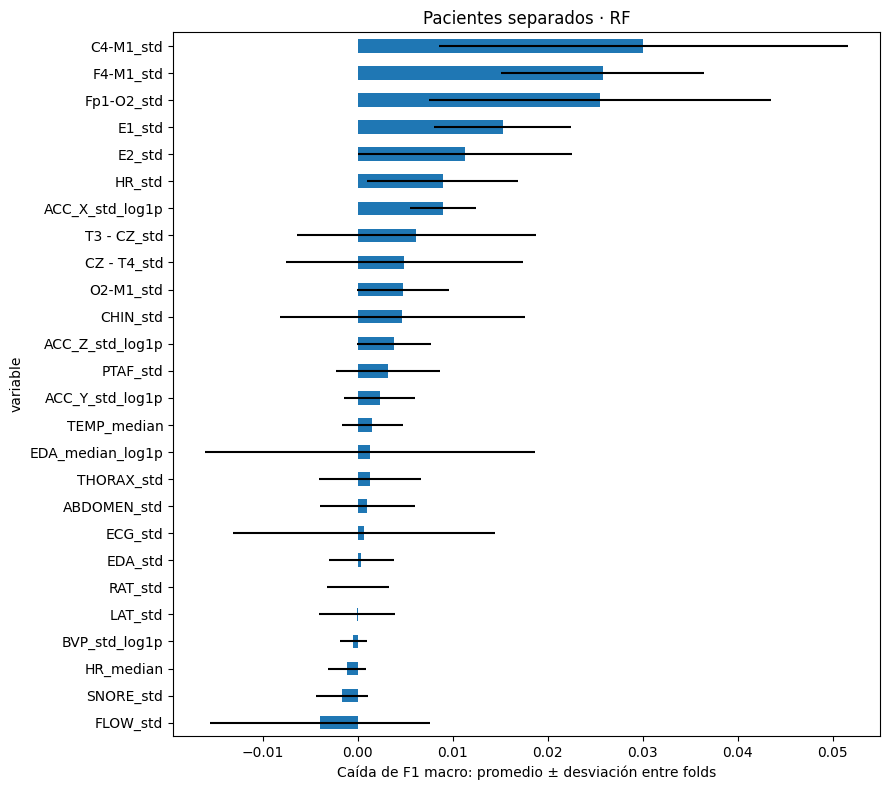

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


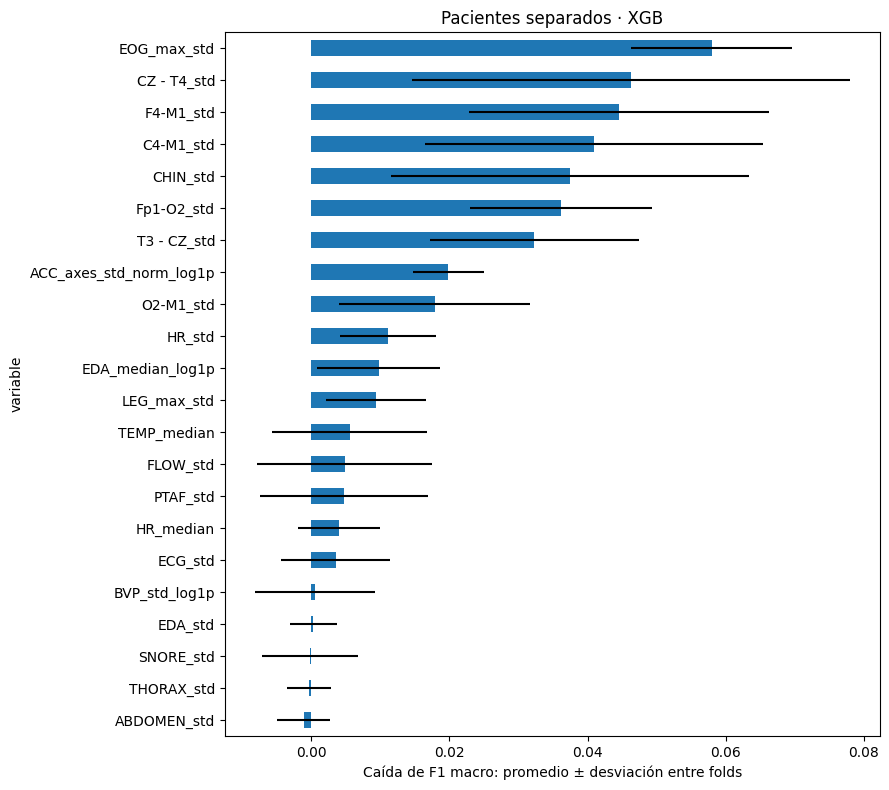

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


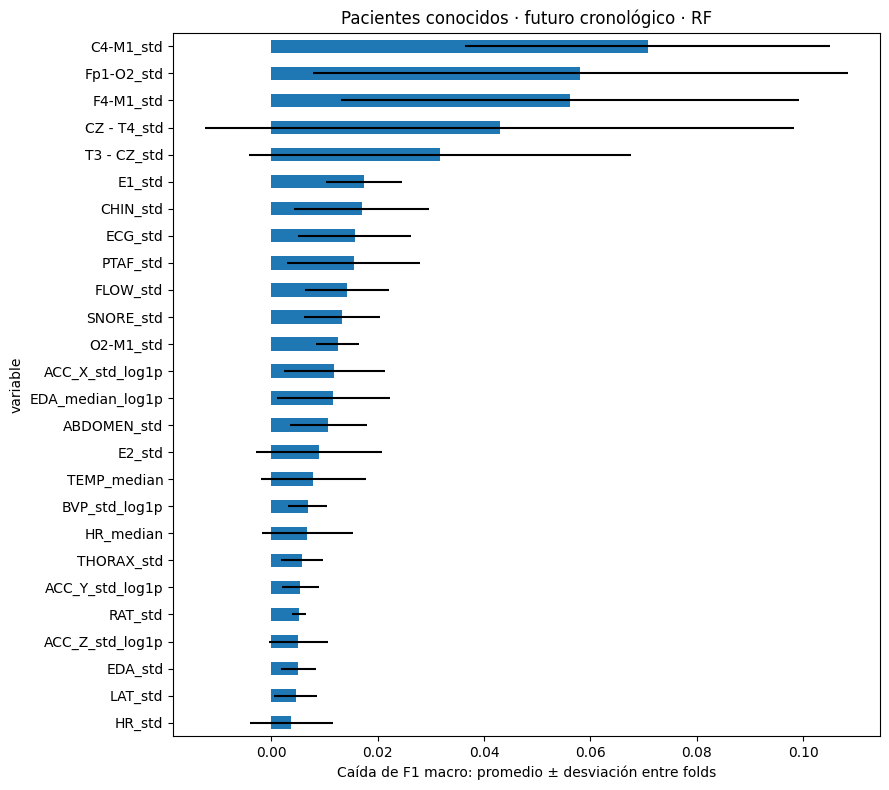

Fold 1/5 terminado.


Fold 2/5 terminado.


Fold 3/5 terminado.


Fold 4/5 terminado.


Fold 5/5 terminado.


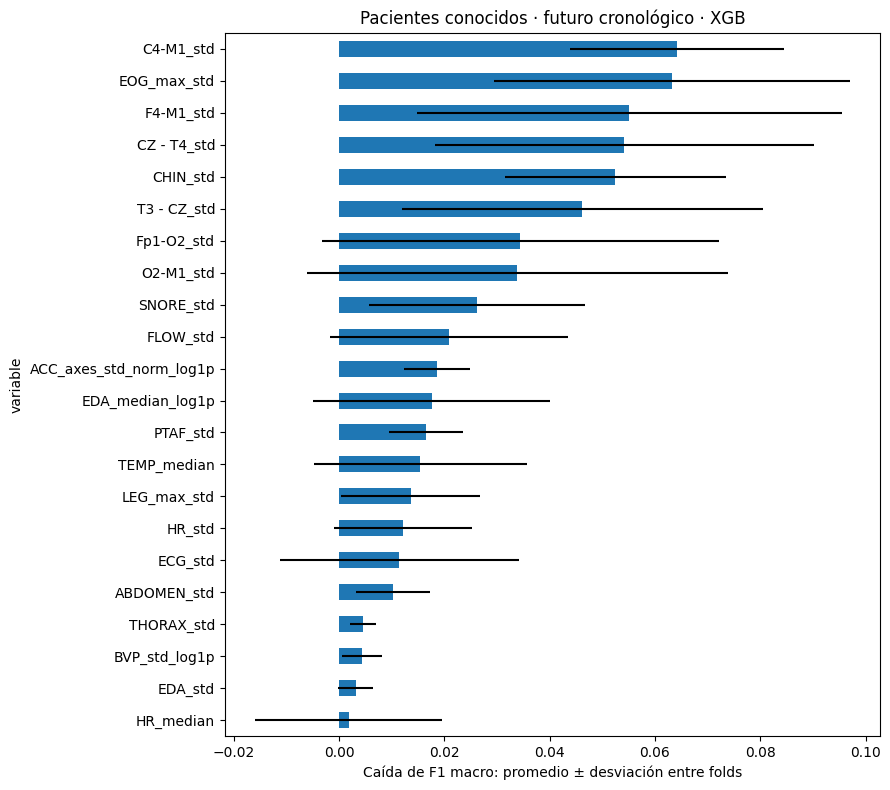

In [13]:
diagnosticos = {}
for protocolo in ESCENARIOS:
    for algoritmo in ['RF','XGB']:
        # Importancia de los mejores modelos sin historia/SMOTE para comparar señales originales.
        nombres = [n for n,r in ajustes.items() if r['configuracion']['protocolo']==protocolo
            and algoritmo_resultado(n)==algoritmo and not n.startswith(('contexto_','smote_','balanceo_'))]
        seleccionado = elegir_nombres(nombres)
        modelo,pesos,escalar,entradas = especificaciones[seleccionado]
        nombre = f'diagnostico_{protocolo}_{algoritmo}'
        r = evaluar(modelo,entradas,nombre,protocolo,pesos,escalar,importancia=True)
        imp = r['importancia'].groupby(['variable','fold']).caida_f1_macro.mean()
        resumen = imp.groupby('variable').agg(['mean','std']).sort_values('mean')
        resumen.to_csv(SALIDA / nombre / 'resumen_importancia.csv')
        resumen['mean'].plot.barh(xerr=resumen['std'],figsize=(9,8))
        plt.xlabel('Caída de F1 macro: promedio ± desviación entre folds')
        plt.title(nombre_protocolo(protocolo)+' · '+algoritmo)
        plt.tight_layout(); plt.savefig(SALIDA / nombre / 'importancia.png'); plt.show()
for protocolo,nombre in candidatos_escenario.items():
    diagnosticos[protocolo] = ajustes[nombre]


### 4.6.2. Errores y matrices de confusión
Reportes y matrices acumulados sobre predicciones OOF elegibles. Los registros largos pesan más. Estos valores no son el promedio entre folds.


**Pacientes separados · acumulado OOF**

,precision,recall,f1-score,support
W,0.5595,0.5973,0.5778,9387.0000
N1,0.2265,0.2592,0.2417,5309.0000
N2,0.8444,0.7044,0.7681,23461.0000
N3,0.4359,0.6186,0.5114,1825.0000
R,0.3820,0.5128,0.4379,5029.0000
macro avg,0.4897,0.5385,0.5074,45011.0000
weighted avg,0.6439,0.6047,0.6190,45011.0000


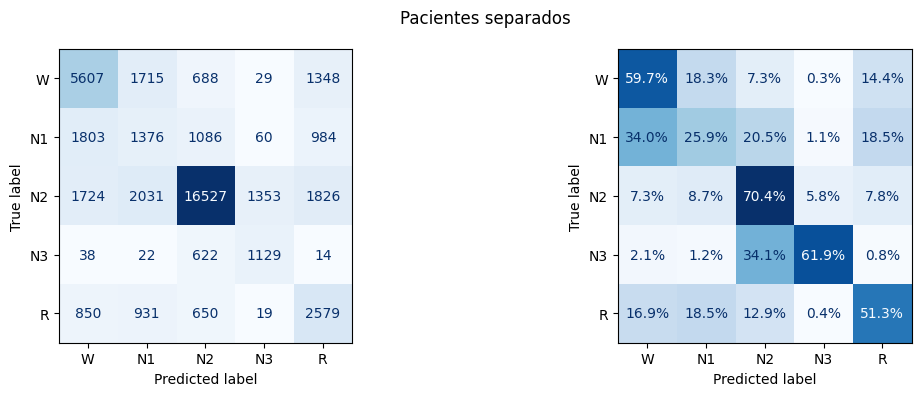

**Pacientes conocidos · futuro cronológico · acumulado OOF**

,precision,recall,f1-score,support
W,0.7064,0.7693,0.7365,7854.0000
N1,0.3134,0.3843,0.3452,4260.0000
N2,0.8193,0.8335,0.8264,19327.0000
N3,0.5578,0.6936,0.6183,1113.0000
R,0.7010,0.3791,0.4920,4936.0000
macro avg,0.6196,0.6119,0.6037,37490.0000
weighted avg,0.7149,0.7050,0.7027,37490.0000


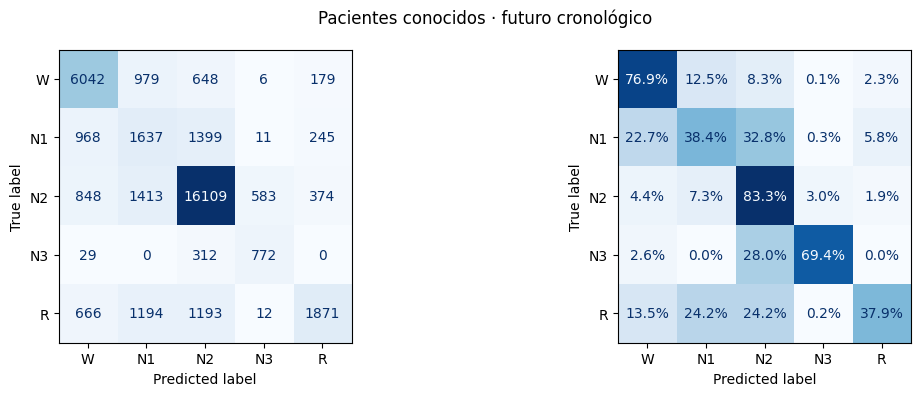

In [14]:
def diagnosticar_errores(datos,nombre,carpeta):
    carpeta.mkdir(exist_ok=True)
    reporte = pd.DataFrame(classification_report(datos.real,datos.predicha,labels=range(5),
        target_names=ETAPAS,output_dict=True,zero_division=0)).T
    reporte.to_csv(carpeta / 'reporte.csv')
    mostrar_tabla(reporte.loc[ETAPAS+['macro avg','weighted avg']],nombre+' · acumulado OOF')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,norma in zip(axes,[None,'true']):
        ConfusionMatrixDisplay.from_predictions(datos.real,datos.predicha,labels=range(5),
            display_labels=ETAPAS,normalize=norma,values_format='.1%' if norma else 'd',
            cmap='Blues',colorbar=False,ax=ax)
    fig.suptitle(nombre); fig.tight_layout(); fig.savefig(carpeta/'matriz.png'); plt.show()

def diagnosticar_curvas(datos,nombre,carpeta,tipo):
    carpeta.mkdir(exist_ok=True)
    fig,axes=plt.subplots(1,5,figsize=(20,4))
    filas=[]
    for c,etapa in enumerate(ETAPAS):
        binaria=datos.real.to_numpy()==c
        if not binaria.any() or binaria.all():
            axes[c].set_title(etapa+': no evaluable')
            filas.append(dict(etapa=etapa,valor=np.nan)); continue
        prob=datos[f'prob_{etapa}'].to_numpy()
        if tipo=='pr':
            precision,recall,_=precision_recall_curve(binaria,prob)
            valor=average_precision_score(binaria,prob)
            axes[c].plot(recall,precision,label=f'AP={valor:.3f}')
            axes[c].axhline(binaria.mean(),ls='--',color='gray',label='Prevalencia')
            tp=((datos.predicha.to_numpy()==c)&binaria).sum()
            axes[c].scatter([tp/binaria.sum()],[tp/max((datos.predicha==c).sum(),1)],label='Argmax')
            axes[c].set(xlabel='Recuperación',ylabel='Precisión')
        else:
            fp,tp,_=roc_curve(binaria,prob)
            valor=roc_auc_score(binaria,prob)
            axes[c].plot(fp,tp,label=f'AUC={valor:.3f}')
            axes[c].plot([0,1],[0,1],'--',color='gray')
            axes[c].set(xlabel='Tasa de falsos positivos',ylabel='Recuperación')
        axes[c].set(title=etapa,xlim=(0,1),ylim=(0,1.02)); axes[c].legend()
        filas.append(dict(etapa=etapa,valor=valor))
    fig.suptitle(nombre); fig.tight_layout(); fig.savefig(carpeta/f'{tipo}.png'); plt.show()
    tabla=pd.DataFrame(filas).set_index('etapa').rename(columns={'valor':'AP' if tipo=='pr' else 'ROC-AUC'})
    tabla.to_csv(carpeta/f'{tipo}.csv'); mostrar_tabla(tabla)

def diagnosticar_pacientes(datos,nombre,carpeta):
    carpeta.mkdir(exist_ok=True)
    filas=[]
    for paciente,g in datos.groupby('patient_id'):
        filas.append(dict(Paciente=paciente,Epochs=len(g),Etapas=g.real.nunique(),
            F1_macro=f1_score(g.real,g.predicha,labels=range(5),average='macro',zero_division=0),
            Exactitud=accuracy_score(g.real,g.predicha)))
    tabla=pd.DataFrame(filas).sort_values('F1_macro')
    tabla.to_csv(carpeta/'pacientes.csv',index=False)
    mostrar_tabla(tabla.head(5),nombre+' · cinco pacientes con menor F1')
    mostrar_tabla(tabla[['F1_macro','Exactitud']].agg(['mean','std','min','max']), 'Dispersión entre pacientes')

def diagnosticar(datos,nombre,carpeta):
    diagnosticar_errores(datos,nombre,carpeta)
    diagnosticar_curvas(datos,nombre,carpeta,'pr')
    diagnosticar_curvas(datos,nombre,carpeta,'roc')
    diagnosticar_pacientes(datos,nombre,carpeta)

for protocolo,r in diagnosticos.items():
    diagnosticar_errores(r['oof'],nombre_protocolo(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


### 4.6.3. Precision-Recall y Average Precision
X: recuperación, proporción de casos reales detectados. Y: precisión, proporción de detecciones correctas. Cada curva varía el umbral de una etapa frente al resto: detectar más casos suele aumentar falsas alarmas. La prevalencia es la referencia horizontal; AP resume la curva. El punto argmax muestra la decisión multiclase actual, no un umbral binario único.


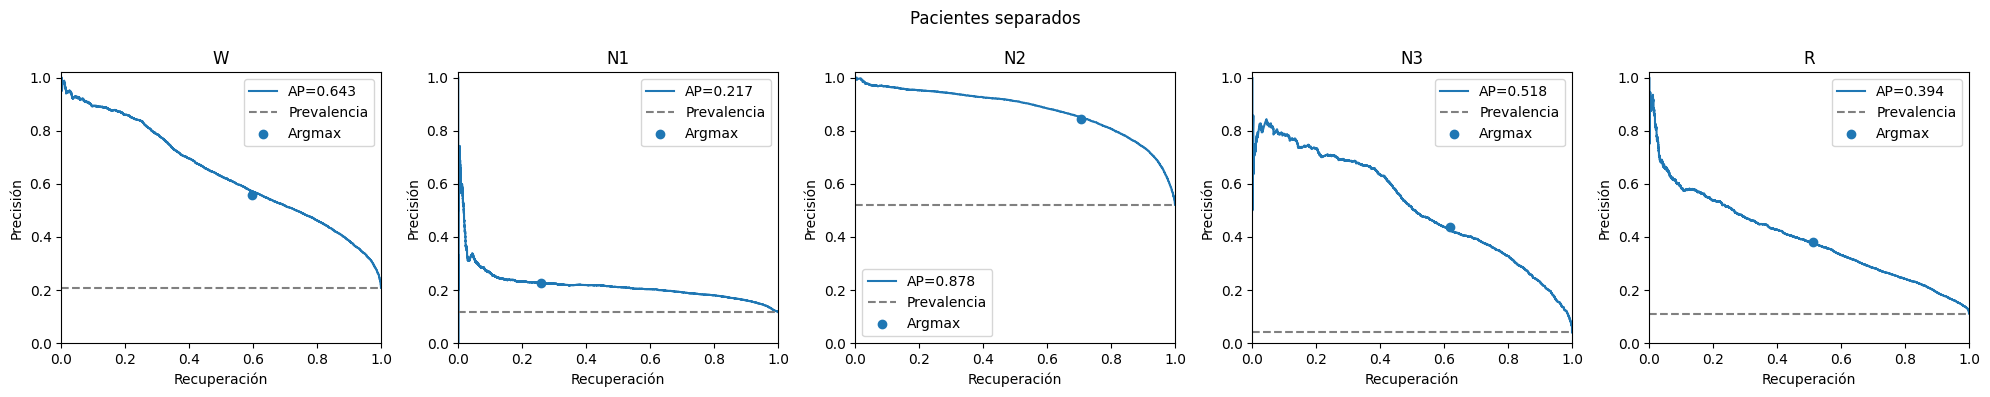

,AP
etapa,
W,0.6426
N1,0.2173
N2,0.8777
N3,0.5185
R,0.3943


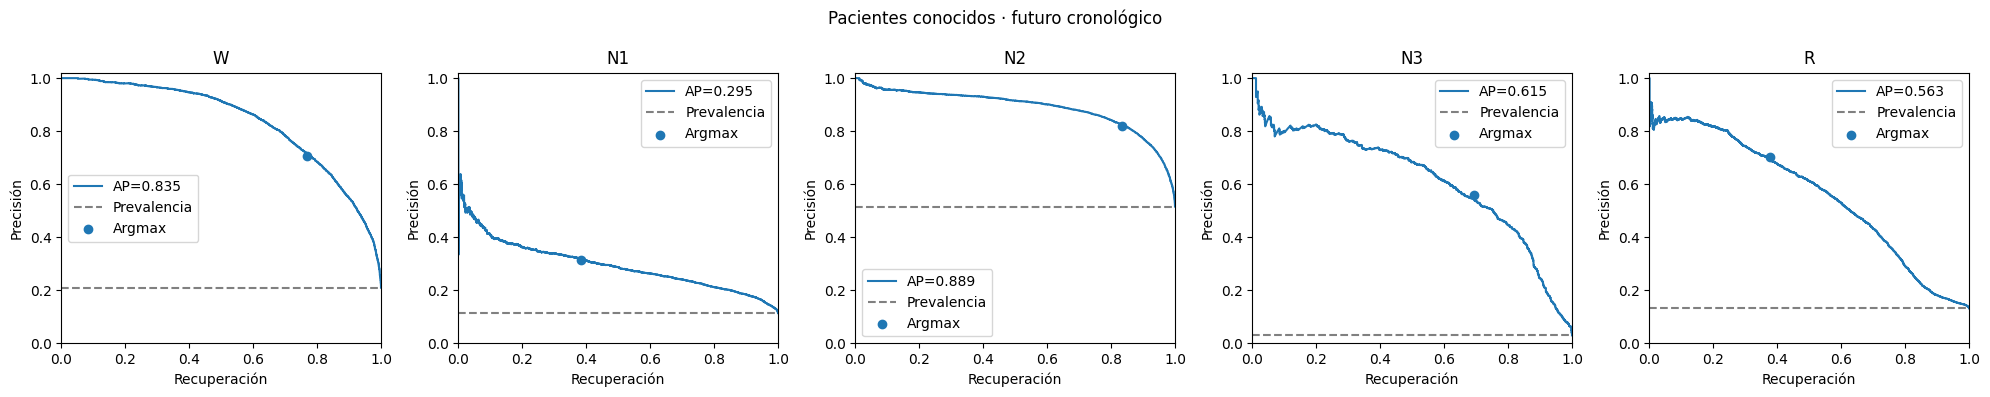

,AP
etapa,
W,0.8353
N1,0.2952
N2,0.8891
N3,0.6148
R,0.5633


In [15]:
for protocolo,r in diagnosticos.items():
    diagnosticar_curvas(r['oof'],nombre_protocolo(protocolo),SALIDA/f'diagnostico_final_{protocolo}','pr')


### 4.6.4. ROC-AUC
Recuperación frente a tasa de falsos positivos. AUC complementa PR; una tasa pequeña puede representar muchas falsas detecciones si la etapa es minoritaria. No reemplaza precisión, recuperación ni AP.


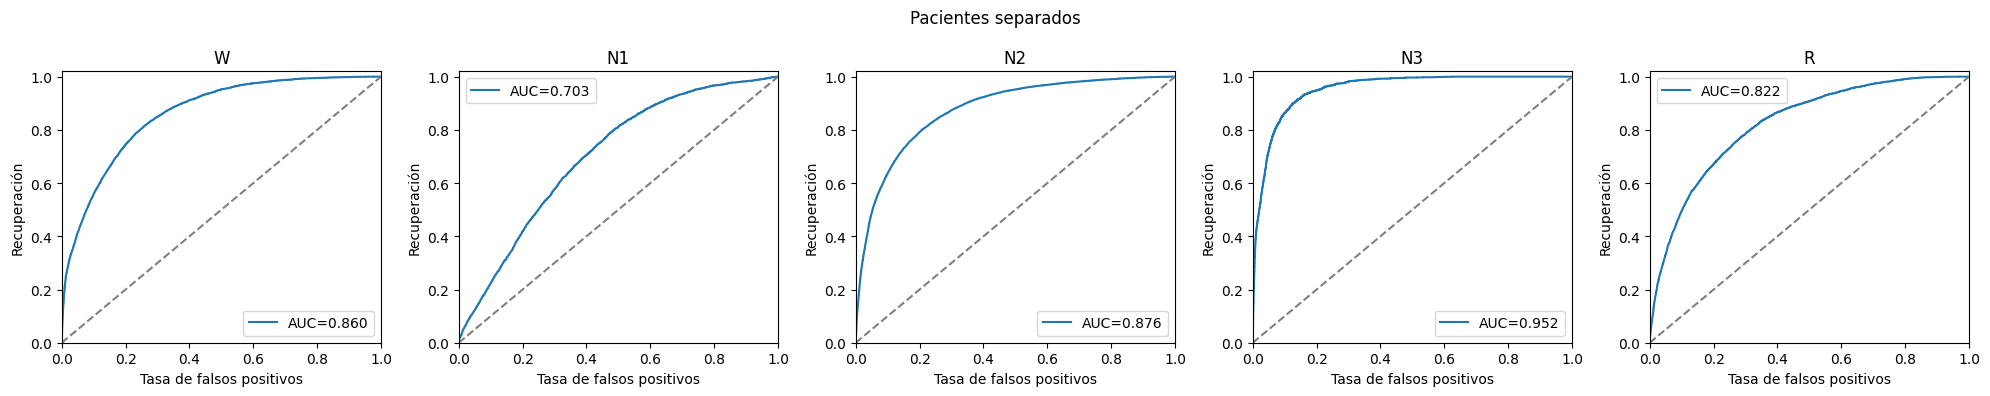

,ROC-AUC
etapa,
W,0.8602
N1,0.7030
N2,0.8758
N3,0.9522
R,0.8222


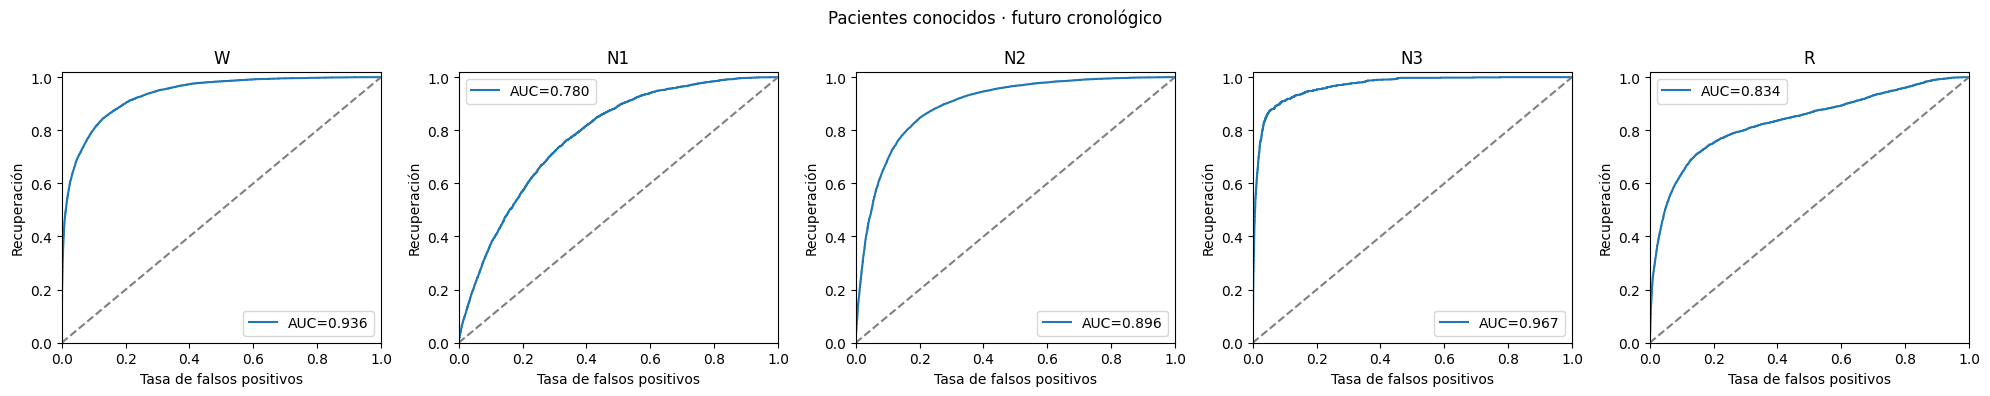

,ROC-AUC
etapa,
W,0.9362
N1,0.7804
N2,0.8959
N3,0.9666
R,0.8335


In [16]:
for protocolo,r in diagnosticos.items():
    diagnosticar_curvas(r['oof'],nombre_protocolo(protocolo),SALIDA/f'diagnostico_final_{protocolo}','roc')


### 4.6.5. Resultados por paciente
F1 sobre cinco etapas fijas y cobertura explícita. Etapas ausentes limitan la comparación entre pacientes. En el escenario cronológico se evalúa solo el futuro elegible; no se comparan personas como si tuvieran idénticos registros.


In [17]:
for protocolo,r in diagnosticos.items():
    diagnosticar_pacientes(r['oof'],nombre_protocolo(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


**Pacientes separados · cinco pacientes con menor F1**

,Paciente,Epochs,Etapas,F1_macro,Exactitud
29,39,839,4,0.0743,0.1335
20,27,532,4,0.1873,0.3534
51,82,660,3,0.2084,0.3242
52,84,687,4,0.2215,0.3785
44,59,753,5,0.2494,0.3785


**Dispersión entre pacientes**

,F1_macro,Exactitud
mean,0.4010,0.6029
std,0.1254,0.1405
min,0.0743,0.1335
max,0.6604,0.7959


**Pacientes conocidos · futuro cronológico · cinco pacientes con menor F1**

,Paciente,Epochs,Etapas,F1_macro,Exactitud
20,27,443,4,0.2082,0.5214
51,82,550,3,0.3079,0.8600
44,59,627,4,0.3114,0.5199
1,4,670,4,0.3129,0.6209
18,25,578,4,0.3231,0.5813


**Dispersión entre pacientes**

,F1_macro,Exactitud
mean,0.4322,0.7052
std,0.0870,0.0943
min,0.2082,0.5199
max,0.6379,0.9146


## 4.7. Solo wearable · pendiente
`X_wearable` se definirá con HR_median, HR_std, TEMP_median, EDA_median, EDA_std, BVP_std, ACC_X_std, ACC_Y_std y ACC_Z_std, sin columnas PSG.

Comparación secundaria posterior con modelo independiente y la misma representación wearable
en ambos escenarios para aislar el aporte PSG. No se ejecuta en esta etapa.



## 4.8. Congelación y evaluación final · personas nuevas
Ejecutar **solo desde esta sección**, con kernel reiniciado: no requiere volver a ejecutar 4.1–4.7. La configuración y partición aprobadas quedan incorporadas en este bloque; se validan las huellas de ambos CSV. Las secciones anteriores conservan todas sus salidas de desarrollo.

Primera apertura: autorización explícita mediante `AUTORIZAR_APERTURA_TEST_FINAL`. Después, dejarlo en False: si existen resultados completos se leen sin entrenar ni predecir otra vez. Un estado incompleto detiene la ejecución para conservar la evidencia. No borrar el marcador ni cambiar parámetros usando el test.

### 4.8.1. Configuración congelada y ejecución independiente
XGBoost ponderado, 200 rondas, profundidad 4, tasa 0,1, lambda 5, muestreo de filas/columnas 0,8, semilla 42. Historia de 1+2 minutos: 68 entradas, indicadores y mediana de desarrollo; sin escalado ni SMOTE. Selección por F1 macro de validación, antes de abrir test.

In [1]:
# 4.8 · Ejecución independiente: ejecutar desde esta celda con kernel limpio.
from pathlib import Path
import sys
import json
import hashlib
import platform
import importlib.metadata
from datetime import datetime, timezone
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from IPython import get_ipython
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    average_precision_score, roc_curve, roc_auc_score)
import joblib

RAIZ_FINAL = Path.cwd()
for lugar in [RAIZ_FINAL, RAIZ_FINAL.parent]:
    dependencia = lugar / 'output/modelado-deps'
    if dependencia.is_dir():
        sys.path.insert(0, str(dependencia.resolve()))
    if (lugar / 'etl_v1/dataset_modelado_candidato.csv').exists():
        RAIZ_FINAL = lugar
        break
from xgboost import XGBClassifier
if getattr(get_ipython(), 'kernel', None) is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

PLANTILLA_FINAL = json.loads('{\n  "configuracion": "contexto_pacientes_XGB_lag_1+2",\n  "protocolo": "pacientes",\n  "semilla": 42,\n  "etapas": [\n    "W",\n    "N1",\n    "N2",\n    "N3",\n    "R"\n  ],\n  "parametros": {\n    "objective": "multi:softprob",\n    "base_score": null,\n    "booster": null,\n    "callbacks": null,\n    "colsample_bylevel": null,\n    "colsample_bynode": null,\n    "colsample_bytree": 0.8,\n    "device": null,\n    "early_stopping_rounds": null,\n    "enable_categorical": true,\n    "eval_metric": "mlogloss",\n    "feature_types": null,\n    "feature_weights": null,\n    "gamma": null,\n    "grow_policy": null,\n    "importance_type": null,\n    "interaction_constraints": null,\n    "learning_rate": 0.1,\n    "max_bin": null,\n    "max_cat_threshold": null,\n    "max_cat_to_onehot": null,\n    "max_delta_step": null,\n    "max_depth": 4,\n    "max_leaves": null,\n    "min_child_weight": null,\n    "missing": NaN,\n    "monotone_constraints": null,\n    "multi_strategy": null,\n    "n_estimators": 200,\n    "n_jobs": -1,\n    "num_parallel_tree": null,\n    "random_state": 42,\n    "reg_alpha": null,\n    "reg_lambda": 5,\n    "sampling_method": null,\n    "scale_pos_weight": null,\n    "subsample": 0.8,\n    "tree_method": "hist",\n    "validate_parameters": null,\n    "verbosity": null,\n    "num_class": 5\n  },\n  "columnas": [\n    "HR_median",\n    "HR_std",\n    "TEMP_median",\n    "EDA_std",\n    "C4-M1_std",\n    "F4-M1_std",\n    "O2-M1_std",\n    "Fp1-O2_std",\n    "T3 - CZ_std",\n    "CZ - T4_std",\n    "CHIN_std",\n    "ECG_std",\n    "SNORE_std",\n    "PTAF_std",\n    "FLOW_std",\n    "THORAX_std",\n    "ABDOMEN_std",\n    "EOG_max_std",\n    "LEG_max_std",\n    "BVP_std_log1p",\n    "EDA_median_log1p",\n    "ACC_axes_std_norm_log1p",\n    "HR_median__lag1m",\n    "HR_std__lag1m",\n    "TEMP_median__lag1m",\n    "EDA_std__lag1m",\n    "C4-M1_std__lag1m",\n    "F4-M1_std__lag1m",\n    "O2-M1_std__lag1m",\n    "Fp1-O2_std__lag1m",\n    "T3 - CZ_std__lag1m",\n    "CZ - T4_std__lag1m",\n    "CHIN_std__lag1m",\n    "ECG_std__lag1m",\n    "SNORE_std__lag1m",\n    "PTAF_std__lag1m",\n    "FLOW_std__lag1m",\n    "THORAX_std__lag1m",\n    "ABDOMEN_std__lag1m",\n    "EOG_max_std__lag1m",\n    "LEG_max_std__lag1m",\n    "BVP_std_log1p__lag1m",\n    "EDA_median_log1p__lag1m",\n    "ACC_axes_std_norm_log1p__lag1m",\n    "historia_disponible__lag1m",\n    "HR_median__lag2m",\n    "HR_std__lag2m",\n    "TEMP_median__lag2m",\n    "EDA_std__lag2m",\n    "C4-M1_std__lag2m",\n    "F4-M1_std__lag2m",\n    "O2-M1_std__lag2m",\n    "Fp1-O2_std__lag2m",\n    "T3 - CZ_std__lag2m",\n    "CZ - T4_std__lag2m",\n    "CHIN_std__lag2m",\n    "ECG_std__lag2m",\n    "SNORE_std__lag2m",\n    "PTAF_std__lag2m",\n    "FLOW_std__lag2m",\n    "THORAX_std__lag2m",\n    "ABDOMEN_std__lag2m",\n    "EOG_max_std__lag2m",\n    "LEG_max_std__lag2m",\n    "BVP_std_log1p__lag2m",\n    "EDA_median_log1p__lag2m",\n    "ACC_axes_std_norm_log1p__lag2m",\n    "historia_disponible__lag2m"\n  ],\n  "columnas_actuales": [\n    "HR_median",\n    "HR_std",\n    "TEMP_median",\n    "EDA_std",\n    "C4-M1_std",\n    "F4-M1_std",\n    "O2-M1_std",\n    "Fp1-O2_std",\n    "T3 - CZ_std",\n    "CZ - T4_std",\n    "CHIN_std",\n    "ECG_std",\n    "SNORE_std",\n    "PTAF_std",\n    "FLOW_std",\n    "THORAX_std",\n    "ABDOMEN_std",\n    "EOG_max_std",\n    "LEG_max_std",\n    "BVP_std_log1p",\n    "EDA_median_log1p",\n    "ACC_axes_std_norm_log1p"\n  ],\n  "retardos_minutos": [\n    1,\n    2\n  ],\n  "pesos": "balanced: N_desarrollo / (5 * N_clase_desarrollo)",\n  "imputacion": {\n    "estrategia": "median",\n    "keep_empty_features": true,\n    "valor_columna_vacia": 0\n  },\n  "escalado": false,\n  "smote": false,\n  "huella": {\n    "dataset_epochs_v1.csv": "97862601b852c7643c932bda11f461b901fcc5f593b32cf995203e2a4e175e17",\n    "dataset_modelado_candidato.csv": "5c653a3457a5bdde108f13d537c30a852330a60aaa3ba54f0d83e04319d8bfc1"\n  },\n  "pacientes_test": [\n    2,\n    6,\n    12,\n    14,\n    20,\n    30,\n    35,\n    37,\n    48,\n    50,\n    53,\n    56,\n    67,\n    83,\n    85,\n    88\n  ],\n  "cantidades": {\n    "desarrollo": {\n      "epochs": 45011,\n      "pacientes": 60\n    },\n    "test": {\n      "epochs": 11839,\n      "pacientes": 16\n    }\n  },\n  "versiones_referencia": {\n    "python": "3.13.3",\n    "numpy": "2.2.4",\n    "pandas": "2.2.3",\n    "scikit-learn": "1.9.0",\n    "xgboost": "3.4.1"\n  },\n  "referencia_validacion": {\n    "f1_macro": 0.5053319358663332,\n    "desviacion": 0.026539724383682222,\n    "exactitud": 0.6042592028248022,\n    "por_etapa": {\n      "N1": {\n        "precision": 0.23748404694614678,\n        "recuperacion": 0.26218767445546654,\n        "f1": 0.2410991656262345\n      },\n      "N2": {\n        "precision": 0.8431207767346981,\n        "recuperacion": 0.7026223307600775,\n        "f1": 0.7657034141513559\n      },\n      "N3": {\n        "precision": 0.45880123272747164,\n        "recuperacion": 0.5977439797810739,\n        "f1": 0.49994382038979585\n      },\n      "R": {\n        "precision": 0.420803723132806,\n        "recuperacion": 0.5089161503611028,\n        "f1": 0.44421862474922297\n      },\n      "W": {\n        "precision": 0.5818402627996347,\n        "recuperacion": 0.5977503743167304,\n        "f1": 0.575694654415057\n      }\n    }\n  },\n  "evolucion": [\n    {\n      "etapa": "Referencia ponderada",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.48591761705606074,\n      "desviacion": 0.029931936662632917,\n      "exactitud": 0.5867350415275501\n    },\n    {\n      "etapa": "Ajuste: reg_lambda=5",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.49066261226225444,\n      "desviacion": 0.03274727203761182,\n      "exactitud": 0.5899156806489223\n    },\n    {\n      "etapa": "Historia de 1+2 minutos",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.5053319358663332,\n      "desviacion": 0.026539724383682222,\n      "exactitud": 0.6042592028248022\n    }\n  ],\n  "exposicion_previa": "EDA y comparaciones anteriores sobre la cohorte completa",\n  "reglas_historia": "Por paciente y segmento de pasos de 30 s; NaN e indicador sin pasado; nunca etiquetas ni futuro."\n}')
EN_KAGGLE_FINAL = platform.system() != 'Windows' and Path('/kaggle/input').is_dir()
DIRECTORIO_FINAL = Path('/kaggle/working/modelado') if EN_KAGGLE_FINAL else RAIZ_FINAL / 'output/modelado'
AUTORIZAR_APERTURA_TEST_FINAL = False  # Activar solo para la primera apertura autorizada.


def hash_archivo_final(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()


def firma_final(objeto):
    return hashlib.sha256(json.dumps(objeto, sort_keys=True, ensure_ascii=False,
        separators=(',', ':'), allow_nan=True).encode('utf-8')).hexdigest()


def json_final(ruta, objeto, exclusivo=False):
    texto = json.dumps(objeto, ensure_ascii=False, indent=2, default=str)
    if exclusivo:
        with Path(ruta).open('x', encoding='utf-8', newline='\n') as archivo:
            archivo.write(texto + '\n')
    else:
        temporal = Path(ruta).with_suffix('.tmp')
        temporal.write_bytes((texto + '\n').encode('utf-8'))
        temporal.replace(ruta)


def tabla_final(tabla, titulo=None):
    if titulo:
        display(Markdown('**' + titulo + '**'))
    display(HTML('<div style="overflow-x:auto; margin-bottom:1em">' + tabla.to_html(
        index=not isinstance(tabla.index, pd.RangeIndex), border=0, max_rows=None,
        max_cols=None, float_format=lambda x: f'{x:.4f}', na_rep='—') + '</div>'))


def historia_final(entradas, tabla, minutos):
    if not entradas.index.equals(tabla.index):
        raise ValueError('Historia desalineada')
    resultado = entradas.copy()
    for _, grupo in tabla.groupby('patient_id', sort=False):
        tiempo = grupo.tiempo_relativo_segundos
        if tiempo.duplicated().any() or not np.isfinite(tiempo).all():
            raise ValueError('Tiempo inválido o repetido dentro de paciente')
    ordenada = tabla.sort_values(['patient_id', 'tiempo_relativo_segundos'])
    diferencias = ordenada.groupby('patient_id').tiempo_relativo_segundos.diff()
    segmentos = (~np.isclose(diferencias.to_numpy(), 30., atol=1e-6, rtol=0)).cumsum()
    grupos = ordenada.assign(segmento=segmentos).groupby(['patient_id', 'segmento'], sort=False)
    for minuto in minutos:
        pasos = int(round(minuto * 2))
        if pasos <= 0 or not np.isclose(pasos * 30, minuto * 60):
            raise ValueError('Retardo incompatible con epochs de 30 segundos')
        anterior = pd.DataFrame(np.nan, index=entradas.index, columns=entradas.columns)
        for _, grupo in grupos:
            anterior.loc[grupo.index] = entradas.loc[grupo.index].shift(pasos).to_numpy()
        anterior.columns = [f'{c}__lag{minuto}m' for c in entradas]
        resultado = pd.concat([resultado, anterior], axis=1)
        resultado[f'historia_disponible__lag{minuto}m'] = anterior.notna().all(axis=1).astype(int)
    return resultado


def leer_datos_final(raiz, configuracion):
    tablas = {}
    claves = ['patient_id', 'epoch']
    comunes = claves + ['Sleep_Stage', 'tiempo_relativo_segundos']
    for nombre, esperado in configuracion['huella'].items():
        ruta = Path(raiz) / 'etl_v1' / nombre
        if not ruta.exists() and EN_KAGGLE_FINAL:
            coincidencias = list(Path('/kaggle/input').rglob(nombre))
            if len(coincidencias) != 1:
                raise ValueError(f'Fuente ambigua o ausente: {nombre}')
            ruta = coincidencias[0]
        if hash_archivo_final(ruta) != esperado:
            raise ValueError(f'Cambió la fuente congelada: {nombre}')
        opciones = {'usecols': comunes} if nombre == 'dataset_epochs_v1.csv' else {}
        tabla = pd.read_csv(ruta, **opciones).sort_values(claves).reset_index(drop=True)
        if tabla[comunes].isna().any().any() or tabla.duplicated(claves).any():
            raise ValueError('Claves/tiempos/etiquetas inválidos')
        if not tabla.Sleep_Stage.isin(configuracion['etapas']).all():
            raise ValueError('Etiqueta desconocida')
        tablas[nombre] = tabla
    candidato = tablas['dataset_modelado_candidato.csv']
    if not tablas['dataset_epochs_v1.csv'][comunes].equals(candidato[comunes]):
        raise ValueError('CSV desalineados en claves, tiempos o etiquetas')
    columnas = configuracion['columnas_actuales']
    if set(columnas) & set(comunes):
        raise ValueError('Identificador, tiempo u objetivo entre predictores')
    if not np.isfinite(candidato[columnas].to_numpy(float)).all():
        raise ValueError('Predictores actuales no finitos')
    mascara = candidato.patient_id.isin(configuracion['pacientes_test'])
    desarrollo = candidato.loc[~mascara].reset_index(drop=True)
    prueba = candidato.loc[mascara].reset_index(drop=True)
    if set(desarrollo.patient_id) & set(prueba.patient_id):
        raise ValueError('Pacientes compartidos')
    if set(prueba.patient_id) != set(configuracion['pacientes_test']):
        raise ValueError('Cambió la asignación de pacientes de test')
    for nombre, tabla in [('desarrollo', desarrollo), ('test', prueba)]:
        if len(tabla) != configuracion['cantidades'][nombre]['epochs'] or tabla.patient_id.nunique() != configuracion['cantidades'][nombre]['pacientes']:
            raise ValueError(f'Cambió la cohorte de {nombre}')
        if set(tabla.Sleep_Stage) != set(configuracion['etapas']):
            raise ValueError(f'Falta cobertura de clases en {nombre}')
    asignacion = Path(raiz) / 'output/modelado/asignacion_pacientes.json'
    if asignacion.exists():
        existente = json.loads(asignacion.read_text(encoding='utf-8'))
        if existente['huella'] != configuracion['huella'] or existente['pacientes_test'] != configuracion['pacientes_test'] or existente['semilla'] != configuracion['semilla']:
            raise ValueError('La asignación guardada difiere de la congelada')
    matrices = [historia_final(t[columnas], t, configuracion['retardos_minutos']) for t in [desarrollo, prueba]]
    for matriz in matrices:
        if list(matriz.columns) != configuracion['columnas'] or np.isinf(matriz.to_numpy(float)).any():
            raise ValueError('Orden de columnas o valores de historia inválidos')
    return desarrollo, prueba, matrices[0], matrices[1]


def metricas_desde_predicciones_final(datos, etapas):
    real, pred = datos.real.to_numpy(), datos.predicha.to_numpy()
    prob = datos[[f'prob_{e}' for e in etapas]].to_numpy()
    if datos.duplicated(['patient_id', 'epoch']).any():
        raise ValueError('Predicciones duplicadas')
    if not np.isfinite(prob).all() or (prob < 0).any() or (prob > 1).any() or not np.allclose(prob.sum(axis=1), 1):
        raise ValueError('Probabilidades inválidas')
    if not np.array_equal(pred, prob.argmax(axis=1)):
        raise ValueError('Clases distintas de argmax')
    if not np.isin(real, range(5)).all():
        raise ValueError('Objetivos inválidos en predicciones')
    p, r, f, s = precision_recall_fscore_support(real, pred, labels=range(5), zero_division=0)
    por_etapa = pd.DataFrame({'etapa': etapas, 'precision': p, 'recuperacion': r, 'f1': f, 'soporte': s})
    curvas = []
    for c, etapa in enumerate(etapas):
        binaria = real == c
        evaluable = binaria.any() and not binaria.all()
        curvas.append(dict(etapa=etapa,
            ap=average_precision_score(binaria, prob[:, c]) if evaluable else np.nan,
            roc_auc=roc_auc_score(binaria, prob[:, c]) if evaluable else np.nan))
    pacientes = []
    for paciente, grupo in datos.groupby('patient_id'):
        pacientes.append(dict(patient_id=paciente, epochs=len(grupo), etapas_presentes=grupo.real.nunique(),
            f1_macro_5_etapas=f1_score(grupo.real, grupo.predicha, labels=range(5), average='macro', zero_division=0),
            exactitud=accuracy_score(grupo.real, grupo.predicha)))
    general = dict(f1_macro=f1_score(real, pred, labels=range(5), average='macro', zero_division=0),
        exactitud=accuracy_score(real, pred), epochs=len(datos), pacientes=datos.patient_id.nunique())
    return general, por_etapa, pd.DataFrame(curvas), pd.DataFrame(pacientes)


def ejecutar_final(raiz, salida, plantilla, autorizar=False):
    """Primera ejecución autorizada o lectura verificada; nunca reabre automáticamente."""
    salida = Path(salida)
    marcador = salida / 'test_abierto.json'
    firma = firma_final(plantilla)
    if marcador.exists():
        estado = json.loads(marcador.read_text(encoding='utf-8'))
        if estado.get('estado') != 'evaluado':
            raise RuntimeError('Apertura incompleta: conservar evidencia; no se reintenta automáticamente')
        if estado['firma_plantilla'] != firma:
            raise ValueError('La configuración solicitada no coincide con la evaluada')
        for nombre, esperado in estado['archivos'].items():
            if hash_archivo_final(salida / nombre) != esperado:
                raise ValueError(f'Cambió un resultado protegido: {nombre}')
        congelada = json.loads((salida / 'configuracion_congelada.json').read_text(encoding='utf-8'))
        datos = pd.read_csv(salida / 'predicciones_test.csv')
        metricas = json.loads((salida / 'metricas_test.json').read_text(encoding='utf-8'))
        return dict(datos=datos, metricas=metricas, congelada=congelada, salida=salida, reutilizado=True)
    if not autorizar:
        raise RuntimeError('Test sin abrir: requiere autorización explícita para la primera evaluación')
    salida.mkdir(parents=True, exist_ok=True)
    carpeta = salida / 'test_final'
    carpeta.mkdir(exist_ok=True)
    protegidos = [salida / 'predicciones_test.csv', salida / 'metricas_test.json',
        carpeta / 'pipeline.joblib', carpeta / 'modelo.ubj']
    if any(p.exists() for p in protegidos):
        raise RuntimeError('Hay artefactos sin marcador completo: no sobrescribir ni reintentar automáticamente')
    versiones = {'python': platform.python_version(), **{p:importlib.metadata.version(p)
        for p in ['numpy','pandas','scikit-learn','xgboost','joblib','matplotlib']}}
    for paquete, version in plantilla['versiones_referencia'].items():
        if paquete in versiones and versiones[paquete] != version:
            raise ValueError(f'Versión diferente a la validación: {paquete}')
    congelada = dict(plantilla, versiones=versiones, firma_plantilla=firma,
        motivo='Selección por F1 macro en desarrollo y autorización explícita del usuario; sin consultar test.',
        congelacion_utc=datetime.now(timezone.utc).isoformat())
    ruta_config = salida / 'configuracion_congelada.json'
    if ruta_config.exists():
        anterior = json.loads(ruta_config.read_text(encoding='utf-8'))
        if anterior['firma_plantilla'] != firma:
            raise ValueError('Ya existe otra congelación; no se sobrescribe')
        congelada = anterior
    else:
        json_final(ruta_config, congelada, exclusivo=True)
    estado = dict(estado='reservado', firma_plantilla=firma)
    json_final(marcador, estado, exclusivo=True)
    desarrollo, prueba, Xdes, Xtest = leer_datos_final(raiz, plantilla)
    etapas = plantilla['etapas']
    ydes = desarrollo.Sleep_Stage.map({e:i for i,e in enumerate(etapas)}).to_numpy()
    pesos = compute_sample_weight('balanced', ydes)
    pd.DataFrame([dict(etapa=e, epochs=int((ydes==c).sum()), peso=float(pesos[ydes==c][0]))
        for c,e in enumerate(etapas)]).to_csv(carpeta / 'pesos_desarrollo.csv', index=False)
    pipe = Pipeline([('imputacion', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('escala', 'passthrough'), ('modelo', XGBClassifier(**plantilla['parametros']))])
    inicio = perf_counter()
    pipe.fit(Xdes, ydes, modelo__sample_weight=pesos)
    tiempo_fit = perf_counter() - inicio
    assert np.array_equal(pipe.classes_, np.arange(5))
    prob_desarrollo = pipe.predict_proba(Xdes)
    pred_desarrollo = prob_desarrollo.argmax(axis=1)
    json_final(carpeta / 'metricas_entrenamiento.json', dict(
        f1_macro=f1_score(ydes,pred_desarrollo,labels=range(5),average='macro',zero_division=0),
        exactitud=accuracy_score(ydes,pred_desarrollo),epochs=len(desarrollo)))
    joblib.dump(pipe, carpeta / 'pipeline.joblib', compress=3)
    pipe.named_steps['modelo'].save_model(carpeta / 'modelo.ubj')
    (carpeta / 'parametros_efectivos.json').write_bytes(
        pipe.named_steps['modelo'].get_booster().save_config().encode('utf-8'))
    cargado = joblib.load(carpeta / 'pipeline.joblib')
    muestra = np.unique(np.linspace(0,len(desarrollo)-1,min(257,len(desarrollo)),dtype=int))
    if not np.array_equal(prob_desarrollo[muestra], cargado.predict_proba(Xdes.iloc[muestra])):
        raise AssertionError('La serialización alteró las probabilidades de desarrollo')
    if not np.array_equal(pipe.named_steps['imputacion'].statistics_, cargado.named_steps['imputacion'].statistics_):
        raise AssertionError('La serialización alteró las medianas')
    json_final(carpeta / 'verificacion_serializacion.json', dict(
        iguales=True, conjunto='desarrollo',epochs_verificados=len(muestra)))
    cobertura = pd.DataFrame([dict(minutos=m,
        desarrollo_disponibles=int(Xdes[f'historia_disponible__lag{m}m'].sum()),
        test_disponibles=int(Xtest[f'historia_disponible__lag{m}m'].sum())) for m in plantilla['retardos_minutos']])
    cobertura.to_csv(carpeta / 'disponibilidad_historia.csv', index=False)
    estado.update(estado='abierto', apertura_utc=datetime.now(timezone.utc).isoformat())
    json_final(marcador, estado)
    inicio = perf_counter()
    probabilidades = cargado.predict_proba(Xtest)  # Única inferencia sobre test.
    tiempo_pred = perf_counter() - inicio
    if probabilidades.shape != (len(prueba),5) or not np.isfinite(probabilidades).all() or (probabilidades<0).any() or (probabilidades>1).any() or not np.allclose(probabilidades.sum(axis=1),1):
        raise ValueError('Salida de probabilidades inválida: no repetir inferencia')
    datos = prueba[['patient_id','epoch','tiempo_relativo_segundos']].copy()
    datos['real'] = prueba.Sleep_Stage.map({e:i for i,e in enumerate(etapas)})
    datos['predicha'] = probabilidades.argmax(axis=1)
    for c,e in enumerate(etapas):
        datos[f'prob_{e}'] = probabilidades[:,c]
    if datos.duplicated(['patient_id','epoch']).any():
        raise ValueError('Predicciones repetidas: no repetir inferencia')
    with (salida / 'predicciones_test.csv').open('x', encoding='utf-8', newline='') as archivo:
        datos.to_csv(archivo,index=False)
    estado.update(estado='predicciones_guardadas')
    json_final(marcador,estado)
    datos = pd.read_csv(salida / 'predicciones_test.csv')
    general, por_etapa, curvas, pacientes = metricas_desde_predicciones_final(datos,etapas)
    general.update(segundos_entrenamiento=tiempo_fit, segundos_prediccion=tiempo_pred)
    json_final(salida / 'metricas_test.json',general,exclusivo=True)
    por_etapa.to_csv(carpeta / 'etapas_test.csv',index=False)
    curvas.to_csv(carpeta / 'curvas_test.csv',index=False)
    pacientes.to_csv(carpeta / 'pacientes_test.csv',index=False)
    for norma,nombre in [(None,'matriz_absoluta.csv'),('true','matriz_normalizada.csv')]:
        pd.DataFrame(confusion_matrix(datos.real,datos.predicha,labels=range(5),normalize=norma),
            index=etapas,columns=etapas).to_csv(carpeta/nombre)
    rutas = [ruta_config, salida/'predicciones_test.csv',salida/'metricas_test.json'] + sorted(p for p in carpeta.iterdir() if p.is_file())
    estado.update(estado='evaluado', archivos={p.relative_to(salida).as_posix():hash_archivo_final(p) for p in rutas})
    json_final(marcador,estado)
    return dict(datos=datos, metricas=general, congelada=congelada, salida=salida, reutilizado=False)


def mostrar_errores_final(resultado):
    d = resultado['datos']
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    for ax,norma in zip(axes,[None,'true']):
        ConfusionMatrixDisplay.from_predictions(d.real,d.predicha,labels=range(5),
            display_labels=resultado['congelada']['etapas'],normalize=norma,
            values_format='.1%' if norma else 'd',cmap='Blues',colorbar=False,ax=ax)
    fig.suptitle('Test interno · personas nuevas'); fig.tight_layout()
    ruta = resultado['salida']/'test_final/matrices.png'
    if not ruta.exists(): fig.savefig(ruta)
    plt.show()


def mostrar_curvas_final(resultado,tipo):
    datos = resultado['datos']; etapas = resultado['congelada']['etapas']
    fig,axes = plt.subplots(1,5,figsize=(20,4))
    valores = []
    for c,e in enumerate(etapas):
        real = datos.real.to_numpy()==c; prob=datos[f'prob_{e}'].to_numpy()
        if not real.any() or real.all():
            axes[c].set_title(e+': no evaluable'); continue
        if tipo=='pr':
            p,r,_=precision_recall_curve(real,prob); valor=average_precision_score(real,prob)
            axes[c].plot(r,p,label=f'AP={valor:.3f}')
            axes[c].axhline(real.mean(),ls='--',color='gray',label='Prevalencia')
            tp=((datos.predicha.to_numpy()==c)&real).sum()
            axes[c].scatter([tp/real.sum()],[tp/max((datos.predicha==c).sum(),1)],label='Argmax')
            axes[c].set(xlabel='Recuperación',ylabel='Precisión')
        else:
            fp,tp,_=roc_curve(real,prob); valor=roc_auc_score(real,prob)
            axes[c].plot(fp,tp,label=f'AUC={valor:.3f}'); axes[c].plot([0,1],[0,1],'--',color='gray')
            axes[c].set(xlabel='Tasa de falsos positivos',ylabel='Recuperación')
        axes[c].set(title=e,xlim=(0,1),ylim=(0,1.02)); axes[c].legend()
        valores.append({'Etapa':e,'AP' if tipo=='pr' else 'ROC-AUC':valor})
    fig.suptitle('Test interno · personas nuevas'); fig.tight_layout()
    ruta = resultado['salida']/f'test_final/{tipo}.png'
    if not ruta.exists(): fig.savefig(ruta)
    plt.show(); tabla_final(pd.DataFrame(valores))

In [2]:
RESULTADO_FINAL = ejecutar_final(RAIZ_FINAL,DIRECTORIO_FINAL,PLANTILLA_FINAL,
    autorizar=AUTORIZAR_APERTURA_TEST_FINAL)
print('Resultados guardados: sin reentrenar ni repetir inferencia.' if RESULTADO_FINAL['reutilizado']
      else 'Evaluación única finalizada; predicciones y modelo guardados.')
tabla_final(pd.DataFrame([{'Modelo':'XGBoost ponderado','Profundidad':4,'Rondas':200,
    'Learning rate':0.1,'Lambda L2':5,'Subsample':0.8,'Colsample':0.8,
    'Historia':'1+2 minutos','Predictores':68,'Semilla':42}]),'Configuración congelada')
tabla_final(pd.DataFrame([{'Conjunto':k,'Epochs':v['epochs'],'Pacientes':v['pacientes']}
    for k,v in PLANTILLA_FINAL['cantidades'].items()]),'Partición conservada')

Evaluación única finalizada; predicciones y modelo guardados.


**Configuración congelada**

Modelo,Profundidad,Rondas,Learning rate,Lambda L2,Subsample,Colsample,Historia,Predictores,Semilla
XGBoost ponderado,4,200,0.1000,5,0.8000,0.8000,1+2 minutos,68,42


**Partición conservada**

Conjunto,Epochs,Pacientes
desarrollo,45011,60
test,11839,16


### 4.8.2. Métricas finales y por etapa
Test: 16 personas diferentes de desarrollo. F1 macro usa las cinco etapas con igual peso; exactitud cuenta todos los aciertos. Estas métricas se calculan desde las predicciones persistidas y no son promedios de folds. El test tuvo exposición histórica en EDA y comparaciones anteriores; no sustituye pacientes externos nuevos.

In [3]:
tabla_final(pd.DataFrame([RESULTADO_FINAL['metricas']]).rename(columns={
    'f1_macro':'F1 macro','exactitud':'Exactitud','epochs':'Epochs','pacientes':'Pacientes',
    'segundos_entrenamiento':'Entrenamiento (s)','segundos_prediccion':'Inferencia (s)'}))
tabla_final(pd.read_csv(DIRECTORIO_FINAL/'test_final/etapas_test.csv').set_index('etapa')
    .rename(columns={'precision':'Precisión','recuperacion':'Recuperación','f1':'F1','soporte':'Soporte'}))

F1 macro,Exactitud,Epochs,Pacientes,Entrenamiento (s),Inferencia (s)
0.5412,0.6126,11839,16,2.9264,0.0213


,Precisión,Recuperación,F1,Soporte
etapa,,,,
W,0.6597,0.5633,0.6077,2842
N1,0.1733,0.2958,0.2185,1224
N2,0.8708,0.6801,0.7637,6076
N3,0.6023,0.5653,0.5832,375
R,0.4245,0.7148,0.5327,1322


### 4.8.3. Errores y matrices de confusión
Filas: etapas reales; columnas: predichas. Se muestran cantidades y recuperación por etapa real. No ajustar el modelo a partir de estas confusiones.

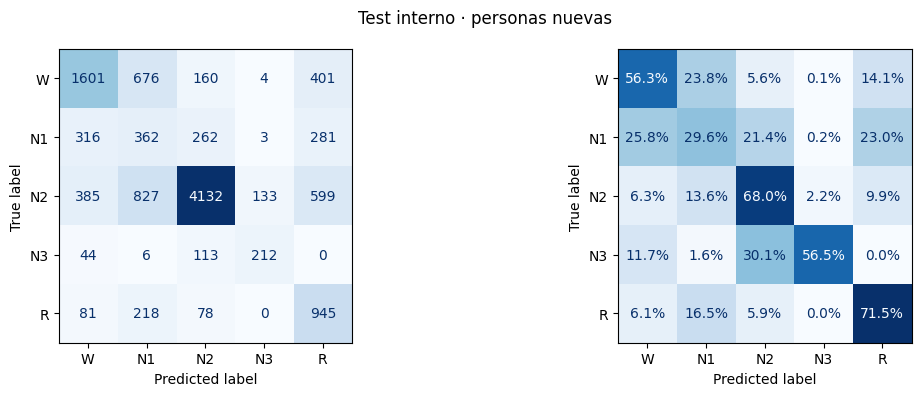

In [4]:
mostrar_errores_final(RESULTADO_FINAL)

### 4.8.4. Precision-Recall y Average Precision
Cada etapa contra el resto. Precisión frente a recuperación al variar el umbral, referencia horizontal de prevalencia y AP. Argmax marca la decisión multiclase congelada; no se optimizan umbrales con test.

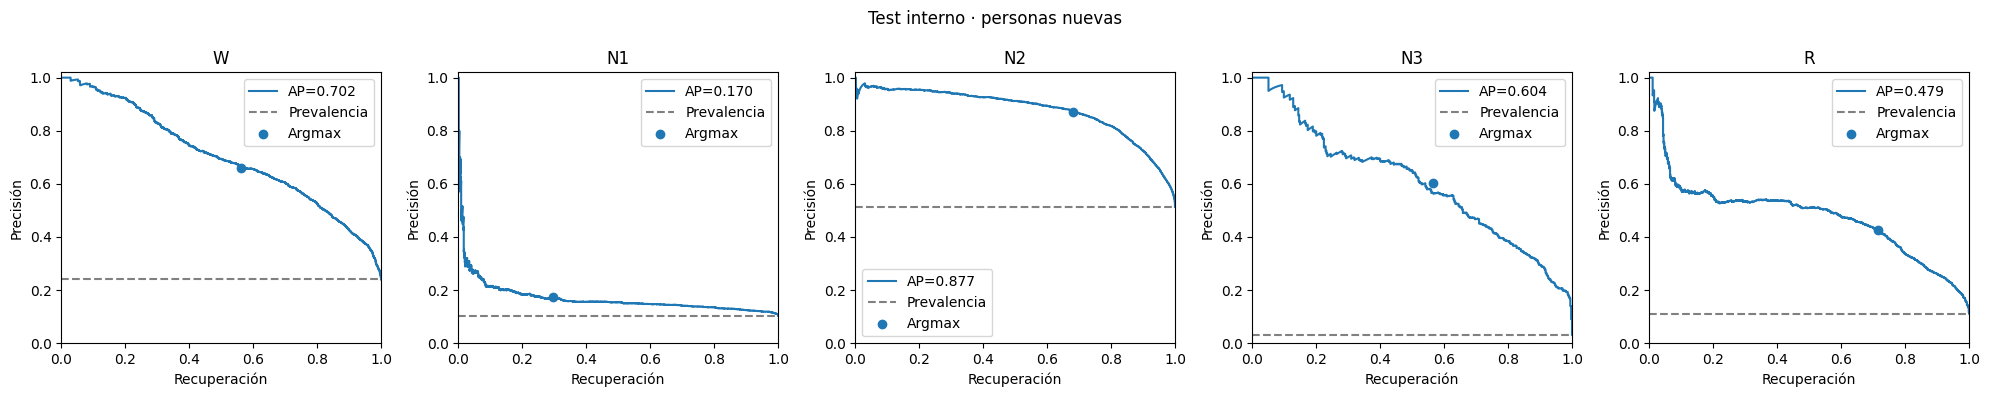

Etapa,AP
W,0.7021
N1,0.1699
N2,0.8774
N3,0.6036
R,0.4794


In [5]:
mostrar_curvas_final(RESULTADO_FINAL,'pr')

### 4.8.5. ROC y ROC-AUC
Diagnóstico complementario a PR. Una ROC-AUC alta no reemplaza precisión y recuperación de una etapa minoritaria.

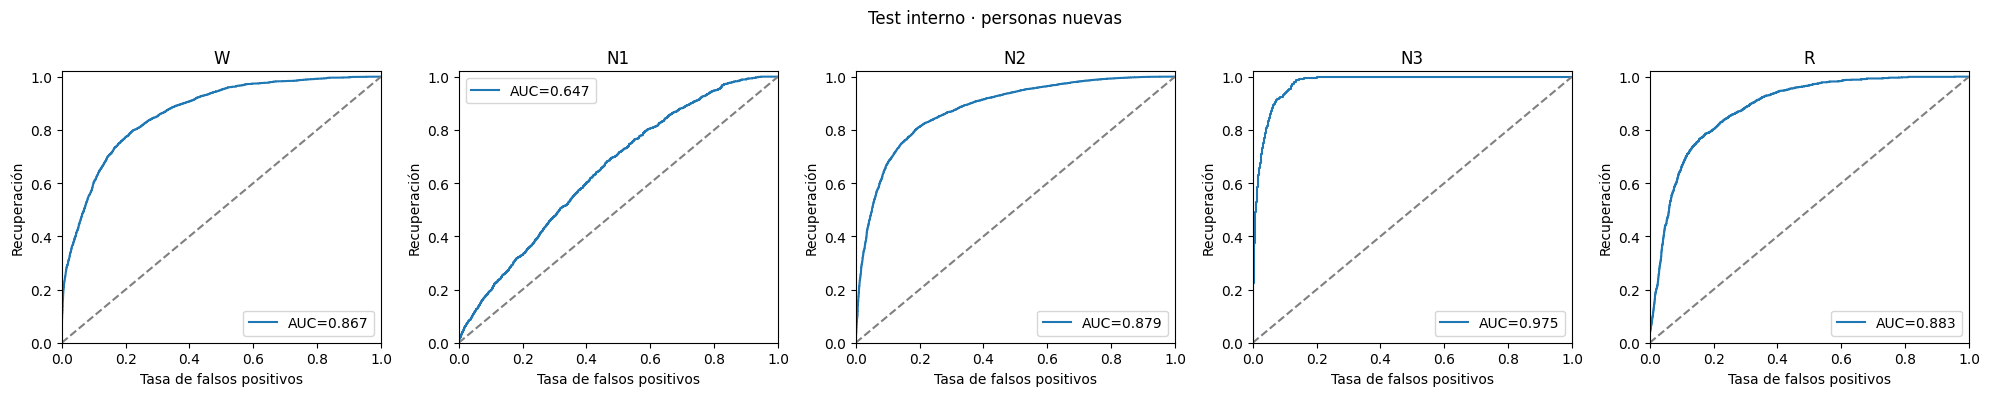

Etapa,ROC-AUC
W,0.8669
N1,0.6471
N2,0.8787
N3,0.9746
R,0.8833


In [6]:
mostrar_curvas_final(RESULTADO_FINAL,'roc')

### 4.8.6. Resultados por paciente
F1 con cinco etapas fijas y cobertura informada. Las personas tienen diferente duración y presencia de etapas; ausencia de clases limita su comparación. Se muestra todo el test: 16 pacientes.

In [7]:
PACIENTES_TEST_FINAL = pd.read_csv(DIRECTORIO_FINAL/'test_final/pacientes_test.csv')
tabla_final(PACIENTES_TEST_FINAL.sort_values('f1_macro_5_etapas').rename(columns={
    'patient_id':'Paciente','epochs':'Epochs','etapas_presentes':'Etapas presentes',
    'f1_macro_5_etapas':'F1 macro (5 etapas)','exactitud':'Exactitud'}))
tabla_final(PACIENTES_TEST_FINAL[['f1_macro_5_etapas','exactitud']].agg(['mean','std','min','max']),
    'Dispersión entre pacientes — no equivale al agregado por epoch')

,Paciente,Epochs,Etapas presentes,F1 macro (5 etapas),Exactitud
13,83,731,4,0.1913,0.3748
14,85,616,4,0.2351,0.3425
12,67,821,4,0.3433,0.3800
1,6,801,4,0.3926,0.5431
0,2,652,4,0.4011,0.5874
9,50,696,5,0.4118,0.8750
10,53,756,4,0.4210,0.5939
15,88,713,4,0.4303,0.5891
11,56,809,4,0.4372,0.6823
2,12,843,4,0.4539,0.6394


**Dispersión entre pacientes — no equivale al agregado por epoch**

,f1_macro_5_etapas,exactitud
mean,0.4288,0.6121
std,0.1117,0.1475
min,0.1913,0.3425
max,0.6369,0.8750


### 4.8.7. Evolución y comparación validación–test
Se conservan las decisiones de desarrollo. Los resultados históricos sobre 76 pacientes no son una réplica de la validación actual sobre 60; se identifican por separado. Validación y test no se promedian. Las diferencias se describen, sin nuevos ajustes.

In [8]:
EVOLUCION_FINAL = pd.DataFrame(PLANTILLA_FINAL['evolucion'] + [dict(etapa='Modelo congelado',
    conjunto='Test · 16 personas nuevas',f1_macro=RESULTADO_FINAL['metricas']['f1_macro'],
    desviacion=np.nan,exactitud=RESULTADO_FINAL['metricas']['exactitud'])])
tabla_final(EVOLUCION_FINAL.rename(columns={'etapa':'Paso','conjunto':'Evaluación','f1_macro':'F1 macro',
    'desviacion':'Desviación entre folds','exactitud':'Exactitud'}))
tabla_final(pd.DataFrame([{'Referencia':'XGBoost ponderado anterior','Cohorte':'76 pacientes · sin test reservado',
    'F1 macro':0.4923,'Desviación entre folds':0.0217,'Exactitud':0.5921}]),
    'Antecedente histórico — otra partición; no atribuir diferencias solo al modelo')
etapas_cv = pd.DataFrame(PLANTILLA_FINAL['referencia_validacion']['por_etapa']).T
etapas_test = pd.read_csv(DIRECTORIO_FINAL/'test_final/etapas_test.csv').set_index('etapa')
comparacion = pd.DataFrame({'F1 validación (media folds)':etapas_cv.f1,
    'F1 test (agregado)':etapas_test.f1,'Precisión test':etapas_test.precision,
    'Recuperación test':etapas_test.recuperacion,'Soporte test':etapas_test.soporte}).reindex(PLANTILLA_FINAL['etapas'])
tabla_final(comparacion,'Comparación por etapa')
diferencia = RESULTADO_FINAL['metricas']['f1_macro'] - PLANTILLA_FINAL['referencia_validacion']['f1_macro']
print(f'F1 test menos validación: {diferencia:+.4f}. Son evaluaciones distintas; no es efecto causal ni prueba de superioridad.')
debil = etapas_test.f1.idxmin()
print(f'Etapa de menor F1 en test: {debil} ({etapas_test.loc[debil,"f1"]:.4f}). No se reajusta el modelo con este resultado.')

Paso,Evaluación,F1 macro,Desviación entre folds,Exactitud
Referencia ponderada,Validación por pacientes · 60 personas,0.4859,0.0299,0.5867
Ajuste: reg_lambda=5,Validación por pacientes · 60 personas,0.4907,0.0327,0.5899
Historia de 1+2 minutos,Validación por pacientes · 60 personas,0.5053,0.0265,0.6043
Modelo congelado,Test · 16 personas nuevas,0.5412,—,0.6126


**Antecedente histórico — otra partición; no atribuir diferencias solo al modelo**

Referencia,Cohorte,F1 macro,Desviación entre folds,Exactitud
XGBoost ponderado anterior,76 pacientes · sin test reservado,0.4923,0.0217,0.5921


**Comparación por etapa**

,F1 validación (media folds),F1 test (agregado),Precisión test,Recuperación test,Soporte test
W,0.5757,0.6077,0.6597,0.5633,2842
N1,0.2411,0.2185,0.1733,0.2958,1224
N2,0.7657,0.7637,0.8708,0.6801,6076
N3,0.4999,0.5832,0.6023,0.5653,375
R,0.4442,0.5327,0.4245,0.7148,1322


F1 test menos validación: +0.0358. Son evaluaciones distintas; no es efecto causal ni prueba de superioridad.
Etapa de menor F1 en test: N1 (0.2185). No se reajusta el modelo con este resultado.


## 4.9. Conclusiones y límites
### Conclusiones previas a la apertura · desarrollo
El siguiente cierre corresponde al estado anterior al test y se conserva para explicar las decisiones:

Los candidatos se calculan en 4.5.5 separadamente para personas nuevas y pacientes conocidos. No elegir un protocolo por obtener un F1 mayor: cambian la población y el momento de evaluación. Las pruebas temporales y SMOTE se ejecutan en 4.5.3/4.5.4; sus conclusiones dependen de los resultados, no de efectos esperados.

El test continúa cerrado y la configuración final sin congelar. Tuvo exposición histórica en EDA y comparaciones previas; pacientes externos futuros permitirán otra evaluación. El test actual evalúa personas nuevas y no reemplaza una prueba cronológica independiente para personas conocidas. La selección entre muchas pruebas puede optimizar en exceso la validación.

Solo wearable, combinaciones de hiperparámetros y combinación SMOTE+historia quedan pendientes. El [informe de modelado](docs/entrega-03/informe-modelado.md) integra antecedentes, evidencia y decisiones para la exposición.

### Evaluación final
Los resultados finales se presentan en 4.8 y en el informe actualizado. La configuración para personas nuevas queda congelada; el test no se incorpora al entrenamiento ni orienta reajustes. Sigue pendiente una prueba temporal independiente para pacientes conocidos y una evaluación externa con personas adicionales.
### Resultado observado y decisión
El test obtuvo F1 macro **0.5412** y exactitud **0.6126** en 11.839 epochs de 16 pacientes. La diferencia frente a la media de validación es +0.0358. La cifra global mayor no prueba superioridad ni estabilidad universal: cambian las personas, la distribución y la cantidad de datos usada para entrenar. No se reajustaron parámetros, señales ni umbrales con este resultado.

**N1 sigue siendo la principal debilidad:** precisión 0.1733, recuperación 0.2958, F1 0.2185, AP 0.1699. Aproximadamente el 82.7 % de las detecciones N1 son falsas y se omite una proporción importante de sus casos reales. El resultado no justifica afirmar buen reconocimiento de todas las etapas.

F1 por paciente, usando cinco clases fijas: mínimo 0.1913, máximo 0.6369. 11 de los 16 pacientes no tienen las cinco etapas observadas; esa cobertura limita comparaciones individuales. La heterogeneidad y los errores de N1 siguen siendo límites relevantes.

Se conserva la configuración evaluada; no se realizaron reajustes posteriores al test. El pipeline incluye el imputador aprendido en desarrollo. Las celdas 4.1–4.7 y sus salidas conservan sus huellas; el test no se incorporó a experimentos anteriores. La lectura posterior de 4.8 no vuelve a entrenar ni a predecir.
